# 61. Curriculum fine-tuning for Cartesian and arbitrary SO(3) corrections

**Starting point:** Notebook 60 checkpoint `002.30/best.pt`, including Transformer, pooler, MLP, and trained 6D head. **Scientific question:** can the fixed-capacity 6D model learn arbitrary-axis corrections when they are introduced gradually, or is the failure caused by optimization, observability, or insufficient features?

**Three stages, one faulted sensor per non-identity sample:** A: 90% Cartesian / 10% arbitrary axes up to 60°. B: 75% / 25%, arbitrary axes up to 120°. C: 50% / 50%, arbitrary axes up to 179°. Cartesian faults keep their original 0–179° distribution in all three stages. True-frame randomization remains physically consistent; no artificial sensor noise.

1. Verify the sampler and gradient flow.
2. Run the **reversible stochastic curriculum** on **16 fixed physical training windows**, but draw new rotation faults each optimizer update; compare against 16 independent validation windows and retain the old Cartesian probes.
3. Optionally run the **capacity/optimization diagnostic** (one vs 16 physical windows, random unseen axes, head-only vs full network).
4. Enable full training with an **epoch-based curriculum** and exact within-this-run resume of AdamW, scheduler, RNG and stage.
5. Run matched one-step and 12-window rollout comparisons against `002.30` (optional `002.27`).

**Important:** this is a **new run directory**. The old Notebook 61 `002.31` checkpoints must not be resumed under the changed augmentation distribution. The curriculum sampler and checkpoint score are separate: the score always uses a fixed 50/50 Cartesian/arbitrary weighting, independent of the current training-stage mixture.


## 1. Imports and repository

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run from the nn-obs-calib repository or a descendant directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.rotation_6d import matrix_to_rotation_6d, rotation_6d_to_matrix
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel, load_6d_pretrained_features
from obscalib.calibration.rotation_6d_update import apply_calibration_6d_update
from obscalib.training.rotation_6d_loss import Calibration6DLossWeights, calibration_6d_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())


Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126 | CUDA: True


## 2. Settings: initialization, sampling and execution switches

In [ ]:
# New directory: the unsuccessful 002.31 run is preserved, NOT resumed with changed augmentation.
RUN_NAME = 'kaist_pooled_calibration_6d_002.31_curriculum_cartesian_arbitrary'
RUN_DIR = ROOT / 'runs' / RUN_NAME
SOURCE_230_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz' / 'best.pt'
SOURCE_227_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'

RANDOM_SEED, TRAIN_AUG_SEED, VAL_AUG_SEED = 12345, 23456, 34567
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0
REFINED_TAU_BY_SENSOR_S = {'imu': 0.0, 'lidar': -0.025, 'lidar_right': -0.035}
RANDOMIZE_TRUE_SENSOR_FRAMES = True
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
STUDENT_T_DOF = 3
FINE_ROTATION_MAX_DEG, FINE_ROTATION_SCALE_DEG = 60.0, 30.0
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 60.0, 179.0
COARSE_PRIOR_PROBABILITY, IDENTITY_PROBABILITY = 0.50, 0.10
ACTIVE_ROTATION_SUPERVISION_WEIGHT = 0.75
LOSS_WEIGHTS = Calibration6DLossWeights(rotation_weight=2.0, rotation_6d_weight=1.0, rotation_chordal_weight=0.0, translation_weight=0.0, time_offset_weight=0.0, translation_scale_m=0.05, time_offset_scale_s=0.05)

# The stage sampler uses these settings. Keep stage selection explicit and auditable.
CURRICULUM_STAGES = (
    dict(name='A_3d60', cartesian_probability=0.90, arbitrary_max_deg=60.0),
    dict(name='B_3d120', cartesian_probability=0.75, arbitrary_max_deg=120.0),
    dict(name='C_3d179', cartesian_probability=0.50, arbitrary_max_deg=179.0),
)


# Optional controlled capacity test. Run only after the stochastic curriculum.
RUN_CAPACITY_TEST = True
CAPACITY_CONDITIONS = (
    dict(name='one_window_60_full', windows=1, max_deg=60.0, trainable='full', steps=600),
    dict(name='one_window_179_full', windows=1, max_deg=179.0, trainable='full', steps=600),
    dict(name='sixteen_windows_179_head', windows=16, max_deg=179.0, trainable='head_only', steps=600),
    dict(name='sixteen_windows_179_full', windows=16, max_deg=179.0, trainable='full', steps=600),
)
CAPACITY_REPORT_EVERY = 100
CAPACITY_LR_HEAD, CAPACITY_LR_TRANSFORMER = 1e-4, 1e-5

# Full run: fixed stage boundaries. Epoch 1..12=A, 13..32=B, 33..FULL_TARGET_EPOCHS=C.
FULL_STAGE_END_EPOCHS = (12, 32)
FULL_TARGET_EPOCHS = 80  # Total, including already-completed epochs when resuming this NEW 002.32 run.
RUN_FULL_TRAINING = True
RESUME_FULL_TRAINING = False
FULL_INIT_FROM_PREFLIGHT_BEST = False
TRAIN_BATCH_SIZE, NUM_WORKERS, GRADIENT_ACCUMULATION_STEPS = 32, 0, 1
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
HEAD_MLP_LR, TRANSFORMER_LR = 2e-5, 2e-6
LR_REDUCE_FACTOR, LR_PATIENCE_PROBES = 0.5, 8
PROBE_EVERY_EPOCHS = 1
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None
SHOW_PLOTS = True

# The scoring objective is FIXED across stages. Never reuse stage mixing ratio for this.
PROBE_CARTESIAN_SCORE_WEIGHT = 0.50
PROBE_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
PROBE_SCORE_ANGLES_DEG = (30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
FULL_PROBE_WINDOWS, FULL_PROBE_BATCH_SIZE, FULL_PROBE_3D_DIRECTIONS = 16, 8, 3
PROBE_SEED = VAL_AUG_SEED + 5_200_000
ZERO_DRIFT_WEIGHT, WORST_PAIR_WEIGHT, NEAR_PI_WEIGHT = 0.15, 0.25, 0.10

EVAL_RUN = False
EVAL_INCLUDE_227 = False
EVAL_WINDOWS, EVAL_BATCH_SIZE, EVAL_3D_DIRECTIONS = 32, 8, 4
EVAL_ANGLES_DEG = (0.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
EVAL_ROLLOUT_SEQUENCES = ('Urban26', 'Urban28')
EVAL_ROLLOUT_STARTS, EVAL_ROLLOUT_TRUTHS, EVAL_ROLLOUT_STEPS = 1, 1, 12
EVAL_ROLLOUT_ANGLES = (0.0, 30.0, 90.0, 150.0, 179.0)
EVAL_ROLLOUT_3D_DIRECTIONS = 3
KAIST_TAU_IMU_S, KAIST_TAU_LIDAR_S, KAIST_TAU_LIDAR_RIGHT_S = 0.0, -0.025, -0.035

assert SOURCE_230_PATH.is_file(), f'Notebook 60 002.30 checkpoint missing: {SOURCE_230_PATH}'
# assert len(CURRICULUM_STAGES) == len(PREFLIGHT_STEPS_BY_STAGE) == 3
assert [s['arbitrary_max_deg'] for s in CURRICULUM_STAGES] == [60., 120., 179.]
assert all(0 <= s['cartesian_probability'] <= 1 for s in CURRICULUM_STAGES)
assert 0 < FULL_STAGE_END_EPOCHS[0] < FULL_STAGE_END_EPOCHS[1] < FULL_TARGET_EPOCHS
assert 0.0 <= COARSE_PRIOR_PROBABILITY <= 1.0 and 0.0 <= IDENTITY_PROBABILITY < 1.0

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Notebook 61 curriculum:', RUN_DIR)
print('Complete model initialization:', SOURCE_230_PATH)
print('Stages:', [(s['name'], s['cartesian_probability'], s['arbitrary_max_deg']) for s in CURRICULUM_STAGES])


Notebook 61 curriculum: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.31_curriculum_cartesian_arbitrary
Complete model initialization: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/best.pt
Stages: [('A_3d60', 0.9, 60.0), ('B_3d120', 0.75, 120.0), ('C_3d179', 0.5, 179.0)]


## 3. KAIST data: exactly the same splits and physical streams as Notebook 60

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)
print("Corrected rig τ [ms]:", {key: 1000.0 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']
Corrected rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

# Check the actual WindowBatch ground truth, not just constructor arguments.
for split_name, split_dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    sample = collate_windows([split_dataset[0]])
    for sensor, expected_s in REFINED_TAU_BY_SENSOR_S.items():
        observed = float(sample.current_calibration[sensor].time_offset.reshape(-1)[0].item())
        assert abs(observed - expected_s) < 2e-6, f"{split_name}/{sensor}: dataset τ={observed} but expected {expected_s}"
    print(f"{split_name}: τ targets [ms] verified:", {sensor: round(float(state.time_offset.reshape(-1)[0]) * 1000, 3) for sensor, state in sample.current_calibration.items()})

# Compare the zero-clock and corrected-clock dataset instances on the same held-out
# physical windows. This checks whether the loader alters raw measurements when the
# rig reference changes; it never deliberately shifts raw timestamps in this notebook.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
zero_clock_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], zero_clock_rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
corrected_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
if len(zero_clock_control) != len(corrected_control):
    raise RuntimeError("Changing calibration τ modified the number of windows. Inspect dataset timestamp processing before training.")
for index in sorted({0, len(zero_clock_control)//2, len(zero_clock_control)-1}):
    old, new = zero_clock_control[index], corrected_control[index]
    for stream_name in old.streams:
        old_stream, new_stream = old.streams[stream_name], new.streams[stream_name]
        torch.testing.assert_close(old_stream.values, new_stream.values, rtol=0, atol=0)
        torch.testing.assert_close(old_stream.timestamps, new_stream.timestamps, rtol=0, atol=0)
        if old_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(old_stream.interval_start_timestamps, new_stream.interval_start_timestamps, rtol=0, atol=0)
print("PASS: refined τ changes calibration reference while preserving native stream measurements and timestamps.")
del zero_clock_control, corrected_control


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
print('Train/validation windows:', len(train_dataset), len(val_dataset))
print('Batches:', len(train_loader), len(val_loader))


Train/validation windows: 2006 418
Batches: 62 14


## 4. Physical augmentation and canonical calibration conventions

In [6]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(enabled=RANDOMIZE_TRUE_SENSOR_FRAMES, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=0.0, rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD)),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(true_calibration_config)

def augmentation_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window, states):
    return WindowBatch(streams=dict(window.streams), current_calibration=states, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)

def apply_independent_prior_faults(states, xi_by_key):
    """Left-multiply rotation ONLY, leaving lever arms, time offsets and healthy sensors untouched."""
    updated = {}
    for key, state in states.items():
        prior = state.transform.clone()
        prior[:, :3, :3] = so3_exp(xi_by_key[key][:, :3]) @ state.transform[:, :3, :3]
        updated[key] = replace(state, transform=prior)
    return updated

print('Physical augmentation matches Notebook 60: randomized true frames, no artificial sensor noise.')


Physical augmentation matches Notebook 60: randomized true frames, no artificial sensor noise.


## 5. Model, complete 002.30 weights and unchanged Notebook 60 rotation loss

In [7]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_230_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
model.freeze_feature_extractor(False)
model.head_6d.requires_grad_(True)
assert all(p.requires_grad for p in model.parameters())

def model_predictions(window, *, model_override=None):
    if tuple(window.current_calibration) != CALIBRATION_KEYS:
        raise ValueError(f'Unexpected key order: {tuple(window.current_calibration)}')
    canonical = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(canonical, calibration_keys=tuple(window.current_calibration))
    return (model if model_override is None else model_override)(tokens)

def parameter_groups(module, *, transformer_lr=TRANSFORMER_LR, other_lr=HEAD_MLP_LR):
    transformer = list(module.transformer_encoder.parameters())
    other = list(module.pooler.parameters()) + list(module.mlp_body.parameters()) + list(module.head_6d.parameters())
    assert len({id(p) for p in transformer + other}) == len(list(module.parameters()))
    return [dict(params=transformer, lr=transformer_lr, name='transformer'), dict(params=other, lr=other_lr, name='pooler_mlp_head')]

print('Loaded COMPLETE 002.30 model, including 6D head. Parameters:', sum(p.numel() for p in model.parameters()))


Loaded COMPLETE 002.30 model, including 6D head. Parameters: 2554570


In [8]:
def rotation_geodesic_deg(R_first, R_second):
    """Numerically stable geodesic SO(3) angle, including near 180°. Shape [...]."""
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))


def compute_6d_objective(window, output):
    """Joint 6D+chordal rotation loss, translation/tau loss, and active-fault emphasis."""
    if window.targets is None:
        raise ValueError('Training requires full GT targets')
    supervised = calibration_6d_loss(output.predictions, window.current_calibration, window.targets, weights=LOSS_WEIGHTS)
    active_terms, active_angle_errors, active_predicted_angles, active_target_angles = [], [], [], []
    for key in CALIBRATION_KEYS:
        state, truth, pred = window.current_calibration[key], window.targets[key], output.predictions[key]
        R_target = truth.next_transform[:, :3, :3] @ state.transform[:, :3, :3].transpose(-1, -2)
        angle_before = rotation_geodesic_deg(state.transform[:, :3, :3], truth.next_transform[:, :3, :3])
        active = angle_before > 1e-3
        if bool(active.any()):
            target_6d = matrix_to_rotation_6d(R_target)
            reg = (pred.rotation_6d - target_6d).square().mean(dim=-1)
            chord = 0.5 * (pred.delta_rotation - R_target).square().sum(dim=(-2, -1))
            active_terms.append((LOSS_WEIGHTS.rotation_6d_weight * reg + LOSS_WEIGHTS.rotation_chordal_weight * chord)[active])
            active_angle_errors.append(rotation_geodesic_deg(pred.delta_rotation[active], R_target[active]).detach())
            active_predicted_angles.append(rotation_geodesic_deg(pred.delta_rotation[active], torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(pred.delta_rotation[active])).detach())
            active_target_angles.append(angle_before[active].detach())
    extra_active = LOSS_WEIGHTS.rotation_weight * torch.cat(active_terms).mean() if active_terms else supervised.total * 0.0
    loss = supervised.total + ACTIVE_ROTATION_SUPERVISION_WEIGHT * extra_active
    with torch.no_grad():
        corrected = apply_calibration_6d_update(window.current_calibration, output.predictions)
        values = {}
        for key in CALIBRATION_KEYS:
            target = window.targets[key]
            state = corrected[key]
            values[f'{key}/rotation_error_deg'] = rotation_geodesic_deg(state.transform[:, :3, :3], target.next_transform[:, :3, :3]).mean().item()
            values[f'{key}/translation_error_cm'] = (100.0 * torch.linalg.vector_norm(state.transform[:, :3, 3] - target.next_transform[:, :3, 3], dim=-1)).mean().item()
            values[f'{key}/tau_error_ms'] = (1000.0 * (state.time_offset - target.next_time_offset).abs()).mean().item()
        values.update({'loss_total': float(loss.detach()), 'loss_supervised': float(supervised.total.detach()), 'loss_active_rotation': float(extra_active.detach()), 'loss_rotation_6d': float(supervised.rotation_6d.detach()), 'loss_rotation_chordal': float(supervised.rotation_chordal.detach()), 'loss_translation': float(supervised.translation.detach()), 'loss_tau': float(supervised.time_offset.detach()), 'active_rotation_error_deg': torch.cat(active_angle_errors).mean().item() if active_angle_errors else 0.0, 'active_target_deg': torch.cat(active_target_angles).mean().item() if active_target_angles else 0.0, 'active_predicted_step_deg': torch.cat(active_predicted_angles).mean().item() if active_predicted_angles else 0.0, 'active_rotation_count': sum(x.numel() for x in active_angle_errors)})
    return loss, values


def metric_average(sums, counts):
    return {key: sums[key] / counts[key] for key in sums}


## 6. Curriculum-aware fault generator and checks

The single-axis (Cartesian) arm always keeps its full 60–179° coarse range. The arbitrary-axis arm uses the truncated Student-t distribution up to 60° in stage A, the 60–120° coarse range in stage B, and 60–179° in stage C. The original fine/coarse probabilities remain unchanged where both are available. Exactly one of three sensors is faulted in each non-identity sample. Fresh faults are drawn **per sample on each optimizer update**, while the 16 stochastic-preflight physical windows remain fixed.


In [9]:
def prior_config_61(*, arbitrary, coarse, coarse_max_deg=COARSE_ROTATION_MAX_DEG):
    if coarse:
        magnitude = PerturbationMagnitudeConfig(maximum=np.deg2rad(coarse_max_deg), minimum=np.deg2rad(COARSE_ROTATION_MIN_DEG), distribution=PerturbationDistribution.UNIFORM)
    else:
        magnitude = PerturbationMagnitudeConfig(maximum=np.deg2rad(FINE_ROTATION_MAX_DEG), scale=np.deg2rad(FINE_ROTATION_SCALE_DEG), degrees_of_freedom=STUDENT_T_DOF, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T)
    return PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=magnitude, translation=None, time_offset=None, one_calibration_per_sample=True, one_rotation_axis_per_sample=not arbitrary, rotation_axes=(True, True, True), one_perturbation_type_per_sample=False)

prior_samplers_61 = {
    'cart_fine': CalibrationPriorPerturber(prior_config_61(arbitrary=False, coarse=False)),
    'cart_coarse': CalibrationPriorPerturber(prior_config_61(arbitrary=False, coarse=True)),
    'arb_fine': CalibrationPriorPerturber(prior_config_61(arbitrary=True, coarse=False)),
    'arb_coarse_120': CalibrationPriorPerturber(prior_config_61(arbitrary=True, coarse=True, coarse_max_deg=120.0)),
    'arb_coarse_179': CalibrationPriorPerturber(prior_config_61(arbitrary=True, coarse=True, coarse_max_deg=179.0)),
}

def curriculum_stage_for_epoch(epoch_zero_based):
    """Deterministic schedule: remains reproducible when resuming from last.pt."""
    return CURRICULUM_STAGES[0 if epoch_zero_based < FULL_STAGE_END_EPOCHS[0] else (1 if epoch_zero_based < FULL_STAGE_END_EPOCHS[1] else 2)]

@torch.no_grad()
def make_training_window(base_window=None, *, generator, stage=None, physical_window=None, return_diagnostics=False):
    """Apply a stage-dependent, single-sensor rotation fault to fresh or fixed physical data."""
    if stage is None:
        raise ValueError('Pass an explicit curriculum stage; never use an implicit global stage')
    if physical_window is None:
        if base_window is None:
            raise ValueError('Either base_window or physical_window must be supplied')
        physical = physical_augmenter(base_window, generator=generator).augmented_window
    else:
        physical = physical_window
    truth = physical.current_calibration
    n = next(iter(truth.values())).transform.shape[0]
    sampled = {name: prior_samplers_61[name](truth, generator=generator)[1] for name in ('cart_fine', 'cart_coarse', 'arb_fine')}
    if stage['arbitrary_max_deg'] > 60.0:
        coarse_key = 'arb_coarse_120' if stage['arbitrary_max_deg'] <= 120.0 else 'arb_coarse_179'
        sampled[coarse_key] = prior_samplers_61[coarse_key](truth, generator=generator)[1]
    else:
        coarse_key = None

    is_cartesian = torch.rand(n, device=DEVICE, generator=generator) < stage['cartesian_probability']
    is_coarse = torch.rand(n, device=DEVICE, generator=generator) < COARSE_PRIOR_PROBABILITY
    is_identity = torch.rand(n, device=DEVICE, generator=generator) < IDENTITY_PROBABILITY
    xi = {}
    for key in CALIBRATION_KEYS:
        cart = torch.where(is_coarse[:, None], sampled['cart_coarse'][key], sampled['cart_fine'][key])
        if coarse_key is None:
            sphere = sampled['arb_fine'][key]
        else:
            sphere = torch.where(is_coarse[:, None], sampled[coarse_key][key], sampled['arb_fine'][key])
        xi[key] = torch.where(is_cartesian[:, None], cart, sphere).masked_fill(is_identity[:, None], 0.0)

    rotations = torch.stack([xi[key][:, :3] for key in CALIBRATION_KEYS], dim=1)
    active_sensor = torch.linalg.vector_norm(rotations, dim=-1) > 1e-9
    angles_deg = torch.rad2deg(torch.linalg.vector_norm(rotations, dim=-1).sum(dim=1))
    assert bool((active_sensor.sum(dim=1) <= 1).all()), 'More than one faulted sensor'
    assert bool(((rotations[is_cartesian & ~is_identity].abs() > 1e-9).sum(dim=(1, 2)) <= 1).all()), 'Cartesian fault is not one-axis'
    assert bool((angles_deg[~is_cartesian & ~is_identity] <= stage['arbitrary_max_deg'] + .03).all()), 'Arbitrary-axis angle exceeded stage maximum'
    assert bool((angles_deg[is_cartesian & ~is_identity] <= COARSE_ROTATION_MAX_DEG + .03).all()), 'Cartesian fault exceeded maximum'
    assert all(bool((xi[key][:, 3:] == 0).all()) for key in CALIBRATION_KEYS)
    window = clone_with_current_calibration(physical, apply_independent_prior_faults(truth, xi))
    if return_diagnostics:
        return window, dict(cartesian=is_cartesian.cpu().numpy(), coarse=is_coarse.cpu().numpy(), identity=is_identity.cpu().numpy(), active_sensor=active_sensor.cpu().numpy(), angle_deg=angles_deg.cpu().numpy(), fault_rotation=rotations.cpu().numpy())
    return window

@torch.no_grad()
def fixed_physical_train_windows(n_windows, seed):
    """A reproducible batch with fixed raw motion and independently randomized true frames."""
    indices = np.unique(np.linspace(0, len(train_dataset) - 1, min(n_windows, len(train_dataset))).round().astype(int))
    base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
    physical = physical_augmenter(base, generator=augmentation_generator(seed)).augmented_window
    return physical, indices

print('Curriculum sampler is ready; Cartesian range unchanged, arbitrary max is stage-dependent.')


Curriculum sampler is ready; Cartesian range unchanged, arbitrary max is stage-dependent.


In [10]:
# Verify geometry, actual selected angle magnitudes, and finite gradients for ALL stages.
smoke_base = window_batch_to(collate_windows([train_dataset[i] for i in (0, 15, 60, 101, 300, 700, 1200, 1900)]), DEVICE, dtype=DTYPE)
smoke_rows = []
for stage_index, stage in enumerate(CURRICULUM_STAGES):
    count_cart, count_arbitrary, max_arbitrary = 0, 0, 0.0
    for repeat in range(32):
        smoke_window, diag = make_training_window(smoke_base, generator=augmentation_generator(TRAIN_AUG_SEED + 90001 + stage_index * 1000 + repeat), stage=stage, return_diagnostics=True)
        mask = ~diag['identity']
        count_cart += int(np.sum(mask & diag['cartesian']))
        count_arbitrary += int(np.sum(mask & ~diag['cartesian']))
        if np.any(mask & ~diag['cartesian']):
            max_arbitrary = max(max_arbitrary, float(np.max(diag['angle_deg'][mask & ~diag['cartesian']])))
        assert all(bool(torch.isfinite(smoke_window.current_calibration[key].transform).all()) for key in CALIBRATION_KEYS)
    smoke_rows.append(dict(stage=stage['name'], cartesian_nonidentity=count_cart, arbitrary_nonidentity=count_arbitrary, sampled_max_arbitrary_deg=max_arbitrary))
    print(stage['name'], 'Cartesian:', count_cart, 'arbitrary:', count_arbitrary, 'max arbitrary:', round(max_arbitrary, 2))

model.train()
smoke_window = make_training_window(smoke_base, generator=augmentation_generator(TRAIN_AUG_SEED + 999), stage=CURRICULUM_STAGES[2])
smoke_out = model_predictions(smoke_window)
smoke_loss, _ = compute_6d_objective(smoke_window, smoke_out)
smoke_loss.backward()
for block in ('transformer_encoder', 'pooler', 'mlp_body', 'head_6d'):
    grads = [p.grad for p in getattr(model, block).parameters() if p.grad is not None]
    assert grads and all(bool(torch.isfinite(g).all()) for g in grads), f'Gradient failure in {block}'
    print(block, 'gradient L2:', round(math.sqrt(sum(float(g.square().sum()) for g in grads)), 5))
assert bool(torch.isfinite(smoke_loss))
model.zero_grad(set_to_none=True)
model.eval()
display(pd.DataFrame(smoke_rows))
print('PASS: all 3 stage samplers, angle limits, and full-model gradients')
del smoke_out, smoke_loss, smoke_window, smoke_base


A_3d60 Cartesian: 201 arbitrary: 27 max arbitrary: 59.64
B_3d120 Cartesian: 190 arbitrary: 45 max arbitrary: 116.7
C_3d179 Cartesian: 106 arbitrary: 116 max arbitrary: 178.57
transformer_encoder gradient L2: 11.03726
pooler gradient L2: 0.68922
mlp_body gradient L2: 0.75559
head_6d gradient L2: 2.85249


,stage,cartesian_nonidentity,arbitrary_nonidentity,sampled_max_arbitrary_deg
0,A_3d60,201,27,59.635036
1,B_3d120,190,45,116.696213
2,C_3d179,106,116,178.571075


PASS: all 3 stage samplers, angle limits, and full-model gradients


## 7. Matched validation bank with a fixed scoring definition

The full angular bank is unchanged from the previous notebook. For **checkpoint selection** the mixture is **always 50% Cartesian / 50% arbitrary**, even in stages A and B. For **scheduler decisions and capacity diagnostics**, a separate *stage score* can restrict arbitrary-axis probes to angles that stage has introduced, while retaining the full Cartesian range. Keeping the two scores separate prevents the evaluation objective from silently changing when the training distribution changes.


In [11]:
def rotation_geodesic_deg(R_first, R_second):
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))

def rotation_axis_cosine(R_pred, R_gt):
    """Signed SO(3) principal axis cosine, undefined for nearly zero rotation or near exact pi."""
    def skew(R):
        return torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    a, b = skew(R_pred), skew(R_gt)
    an, bn = torch.linalg.vector_norm(a, dim=-1), torch.linalg.vector_norm(b, dim=-1)
    cos = (a * b).sum(-1) / (an * bn).clamp_min(1e-12)
    return torch.where((an > 1e-5) & (bn > 1e-5), cos.clamp(-1, 1), torch.full_like(cos, torch.nan))

def fixed_sphere_directions(n, seed):
    """Deterministic uniformly sampled 3D axes. Both + and - signs will be evaluated."""
    rng = np.random.default_rng(int(seed))
    u = rng.normal(size=(n, 3))
    return (u / np.linalg.norm(u, axis=1, keepdims=True)).astype(np.float64)

@torch.no_grad()
def build_probe_bank(dataset, *, n_windows, batch_size, seed, angles, n_sphere_directions):
    """List of fixed augmented windows and metadata; physical windows shared across all faults."""
    indices = np.unique(np.linspace(0, len(dataset) - 1, min(n_windows, len(dataset))).round().astype(int))
    directions_3d = fixed_sphere_directions(n_sphere_directions, seed + 700)
    axis_specs = [('cartesian', axis, tuple(np.eye(3)[j])) for j, axis in enumerate('XYZ')]
    axis_specs += [('arbitrary', f'U{j+1}', tuple(direction)) for j, direction in enumerate(directions_3d)]
    cases = []
    for group_id, start in enumerate(range(0, len(indices), batch_size)):
        chosen = indices[start:start + batch_size]
        base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
        physical = physical_augmenter(base, generator=augmentation_generator(seed + group_id * 1009)).augmented_window
        truth = physical.current_calibration
        n = len(chosen)
        for key in CALIBRATION_KEYS:
            # Exactly one identity probe per sensor/window, not one per direction or sign.
            if 0.0 in angles:
                cases.append(dict(fault_key=key, axis_type='identity', axis='I', axis_vector=(0., 0., 0.), sign=0, angle_deg=0.0, signed_angle_deg=0.0,
                                  window=clone_with_current_calibration(physical, truth), indices=chosen.copy(), group_id=group_id))
            for family, axis, direction in axis_specs:
                vec = torch.tensor(direction, device=DEVICE, dtype=DTYPE)
                for sign in (1, -1):
                    for angle in angles:
                        if angle == 0.0:
                            continue
                        xi = {k: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for k in CALIBRATION_KEYS}
                        xi[key][:, :3] = sign * float(np.deg2rad(angle)) * vec[None, :]
                        prior = apply_independent_prior_faults(truth, xi)
                        cases.append(dict(fault_key=key, axis_type=family, axis=axis, axis_vector=direction, sign=sign, angle_deg=float(angle),
                                          signed_angle_deg=float(sign * angle), window=clone_with_current_calibration(physical, prior), indices=chosen.copy(), group_id=group_id))
    return cases

@torch.inference_mode()
def evaluate_probe_bank(candidate, cases, *, name):
    """One-step SO(3) error, magnitude, directional cosine, and healthy-sensor drift."""
    previous = candidate.training
    candidate.eval()
    records = []
    try:
        I = torch.eye(3, dtype=DTYPE, device=DEVICE)
        for case in cases:
            key, window = case['fault_key'], case['window']
            prior_R = window.current_calibration[key].transform[:, :3, :3]
            truth_R = window.targets[key].next_transform[:, :3, :3]
            required_R = truth_R @ prior_R.transpose(-1, -2)
            before = rotation_geodesic_deg(prior_R, truth_R)
            out = model_predictions(window, model_override=candidate).predictions
            predicted_R = out[key].delta_rotation
            after = rotation_geodesic_deg(predicted_R @ prior_R, truth_R)
            pred_mag = rotation_geodesic_deg(predicted_R, I.expand_as(predicted_R))
            cos = rotation_axis_cosine(predicted_R, required_R)
            healthy = torch.stack([rotation_geodesic_deg(out[healthy_key].delta_rotation, I.expand_as(out[healthy_key].delta_rotation)) for healthy_key in CALIBRATION_KEYS if healthy_key != key]).mean(dim=0)
            if not bool(torch.isfinite(after).all()):
                raise FloatingPointError(f'Nonfinite residual: {name}, {key}, {case["axis"]}')
            if case['angle_deg'] > 0 and not torch.allclose(before, torch.full_like(before, case['angle_deg']), atol=.08, rtol=0):
                raise AssertionError(f'Fault is not the requested angle: {key}, {case["axis"]}, {case["angle_deg"]}')
            for j, index in enumerate(case['indices']):
                b, a = float(before[j]), float(after[j])
                records.append(dict(model=name, fault_key=key, axis_type=case['axis_type'], axis=case['axis'], sign=case['sign'],
                                    angle_deg=case['angle_deg'], signed_angle_deg=case['signed_angle_deg'], physical_index=int(index),
                                    before_deg=b, after_deg=a, relative_remaining=a/b if b > 1e-3 else np.nan,
                                    correction_deg=float(pred_mag[j]), axis_cosine=float(cos[j]), healthy_predicted_drift_deg=float(healthy[j])))
    finally:
        candidate.train(previous)
    return pd.DataFrame.from_records(records)


def probe_metrics(frame, *, arbitrary_max_deg=None, cartesian_score_weight=PROBE_CARTESIAN_SCORE_WEIGHT):
    """Score with fixed family weights; optionally limit 3D angles for a stage-specific score."""
    use = frame.loc[frame.angle_deg.isin(PROBE_SCORE_ANGLES_DEG) & (frame.angle_deg > 0)].copy()
    if arbitrary_max_deg is not None:
        use = use.loc[(use.axis_type == 'cartesian') | (use.angle_deg <= arbitrary_max_deg + 1e-6)]
    group = use.groupby(['fault_key', 'axis_type', 'axis'], as_index=False).agg(relative_remaining=('relative_remaining', 'mean'), mean_after_deg=('after_deg', 'mean'))
    cartesian = group.loc[group.axis_type == 'cartesian']
    arbitrary = group.loc[group.axis_type == 'arbitrary']
    if len(cartesian) != 9 or len(arbitrary) == 0:
        raise RuntimeError(f'Incomplete probe bank: cartesian={len(cartesian)}/9, arbitrary={len(arbitrary)}')
    cart_mean, arb_mean = float(cartesian.relative_remaining.mean()), float(arbitrary.relative_remaining.mean())
    worst = float(group.relative_remaining.max())
    mean = cartesian_score_weight * cart_mean + (1 - cartesian_score_weight) * arb_mean
    # For stage A, only the Cartesian arm has near-179° targets, which is intentional.
    near_pi_values = use.loc[use.angle_deg == 179.0, 'relative_remaining']
    near_pi = float(near_pi_values.mean()) if len(near_pi_values) else 0.0
    zero_values = frame.loc[frame.angle_deg == 0.0, 'after_deg']
    zero = float(zero_values.mean()) if len(zero_values) else 0.0
    score = mean + WORST_PAIR_WEIGHT * max(0.0, worst - mean) + NEAR_PI_WEIGHT * near_pi + ZERO_DRIFT_WEIGHT * zero / 30.0
    metrics = dict(score=score, cartesian_mean=cart_mean, arbitrary_mean=arb_mean, worst_task=worst, near_pi_ratio=near_pi, zero_drift_deg=zero)
    return metrics, group

# Capacity/preflight same-physical probes: fixed GT and raw data, NEW held-out angles and axes.
@torch.no_grad()
def build_physical_probe_bank(physical, indices, *, seed, angles, n_sphere_directions):
    """Build paired fixed-sensor cases without resampling physical augmentation."""
    n = len(indices)
    truth = physical.current_calibration
    axes = [('cartesian', axis, tuple(np.eye(3)[i])) for i, axis in enumerate('XYZ')]
    axes += [('arbitrary', f'U{i+1}', tuple(u)) for i, u in enumerate(fixed_sphere_directions(n_sphere_directions, seed))]
    cases = []
    for fault_key in CALIBRATION_KEYS:
        if 0.0 in angles:
            cases.append(dict(fault_key=fault_key, axis_type='identity', axis='I', axis_vector=(0., 0., 0.), sign=0, angle_deg=0., signed_angle_deg=0., window=clone_with_current_calibration(physical, truth), indices=indices.copy(), group_id=0))
        for family, axis, direction in axes:
            vec = torch.tensor(direction, device=DEVICE, dtype=DTYPE)
            for sign in (1, -1):
                for angle in angles:
                    if angle == 0:
                        continue
                    xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                    xi[fault_key][:, :3] = sign * np.deg2rad(float(angle)) * vec
                    prior = apply_independent_prior_faults(truth, xi)
                    cases.append(dict(fault_key=fault_key, axis_type=family, axis=axis, axis_vector=direction, sign=sign, angle_deg=float(angle), signed_angle_deg=float(sign * angle), window=clone_with_current_calibration(physical, prior), indices=indices.copy(), group_id=0))
    return cases

print('Defined paired Cartesian + arbitrary-axis probes, SO(3) residual and cosine metrics.')


Defined paired Cartesian + arbitrary-axis probes, SO(3) residual and cosine metrics.


## 8. Stochastic **curriculum**, 16 fixed physical training windows

This test is intentionally different from the earlier 700-step preflight. Choose **16 fixed real training windows** and randomize their true sensor frames once. Every optimizer step applies *new* faults, so the network cannot solve the task by memorizing one correction per window. Advance from **60° → 120° → 179°** arbitrary-axis limits, while preserving full-range Cartesian replay. The same model and AdamW state continue between stages.

At each report, measure (1) held-out rotations on **the same 16 physical windows** and (2) **16 independent validation windows**, using fixed probe directions and angles. Report stage-limited scores and fixed full-range scores separately. Restore the original 2.30 model and RNG after all stages. This test is not evidence of capacity by itself; Section 9 provides controlled capacity comparisons.


A_3d60   step=   0/400 | train=nan | fixed 16 stage/full=0.735/0.802 | val 16 stage/full=0.698/0.768 | val Cartesian/3D=0.413/0.821
A_3d60   step=  25/400 | train=0.0959 | fixed 16 stage/full=0.727/0.784 | val 16 stage/full=0.667/0.753 | val Cartesian/3D=0.406/0.810
A_3d60   step=  50/400 | train=0.1201 | fixed 16 stage/full=0.734/0.788 | val 16 stage/full=0.679/0.764 | val Cartesian/3D=0.413/0.815
A_3d60   step=  75/400 | train=0.3516 | fixed 16 stage/full=0.722/0.782 | val 16 stage/full=0.678/0.764 | val Cartesian/3D=0.413/0.813
A_3d60   step= 100/400 | train=0.0703 | fixed 16 stage/full=0.716/0.780 | val 16 stage/full=0.711/0.772 | val Cartesian/3D=0.412/0.823
A_3d60   step= 125/400 | train=0.1211 | fixed 16 stage/full=0.729/0.785 | val 16 stage/full=0.753/0.788 | val Cartesian/3D=0.418/0.832
A_3d60   step= 150/400 | train=0.1842 | fixed 16 stage/full=0.731/0.786 | val 16 stage/full=0.759/0.792 | val Cartesian/3D=0.423/0.832
A_3d60   step= 175/400 | train=0.1282 | fixed 16 stage/ful

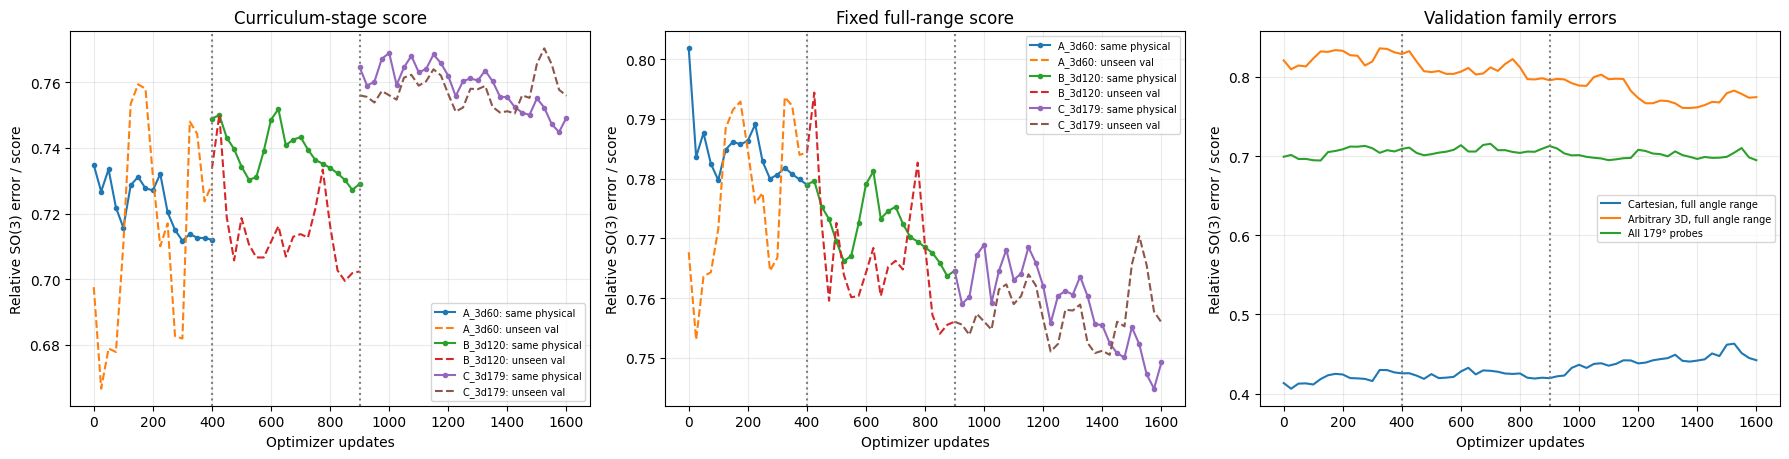

,stage,heldout_stage,val_stage,heldout_global,val_global,val_cart,val_3d,val_179
16,A_3d60,0.712,0.729,0.779,0.784,0.426,0.829,0.709
37,B_3d120,0.729,0.702,0.765,0.756,0.420,0.796,0.713
66,C_3d179,0.749,0.756,0.749,0.756,0.442,0.775,0.695


In [12]:

# Reversible 16-FIXED-WINDOW stochastic curriculum. New faults are drawn on every step.
RUN_STOCHASTIC_PREFLIGHT = True
PREFLIGHT_FIXED_TRAIN_WINDOWS = 16
PREFLIGHT_STEPS_BY_STAGE = (400, 500, 700)
PREFLIGHT_REPORT_EVERY = 25
PREFLIGHT_VALIDATION_WINDOWS, PREFLIGHT_PROBE_BATCH_SIZE, PREFLIGHT_3D_DIRECTIONS = 16, 8, 2
PREFLIGHT_PROBE_ANGLES = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 179.0)

PREFLIGHT_DIR = RUN_DIR / 'stochastic_curriculum_16_windows'
PREFLIGHT_DIR.mkdir(parents=True, exist_ok=True)
PREFLIGHT_BEST_PATH = PREFLIGHT_DIR / 'C_3d179_best_state.pt'
preflight_history = []

if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
    
if RUN_STOCHASTIC_PREFLIGHT:
    fixed_physical, fixed_indices = fixed_physical_train_windows(PREFLIGHT_FIXED_TRAIN_WINDOWS, TRAIN_AUG_SEED + 6_100_100)
    same_physical_cases = build_physical_probe_bank(fixed_physical, fixed_indices, seed=PROBE_SEED + 610, angles=PREFLIGHT_PROBE_ANGLES, n_sphere_directions=PREFLIGHT_3D_DIRECTIONS)
    val_cases = build_probe_bank(val_dataset, n_windows=PREFLIGHT_VALIDATION_WINDOWS, batch_size=PREFLIGHT_PROBE_BATCH_SIZE, seed=PROBE_SEED + 611, angles=PREFLIGHT_PROBE_ANGLES, n_sphere_directions=PREFLIGHT_3D_DIRECTIONS)
    saved_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    saved_training, saved_cpu_rng = model.training, torch.get_rng_state().clone()
    saved_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    saved_np_rng, saved_py_rng = np.random.get_state(), random.getstate()
    pre_optimizer = torch.optim.AdamW(parameter_groups(model, transformer_lr=TRANSFORMER_LR, other_lr=HEAD_MLP_LR), weight_decay=WEIGHT_DECAY)
    pre_generator = augmentation_generator(TRAIN_AUG_SEED + 6_100_000)
    global_pre_step = 0
    try:
        for stage, steps in zip(CURRICULUM_STAGES, PREFLIGHT_STEPS_BY_STAGE):
            best_stage_score = float('inf')
            stage_best_path = PREFLIGHT_DIR / f'{stage["name"]}_best_state.pt'
            for stage_step in range(steps + 1):
                if stage_step:
                    model.train()
                    pre_optimizer.zero_grad(set_to_none=True)
                    # Same physical windows and true frames, but independently resampled priors.
                    batch = make_training_window(generator=pre_generator, physical_window=fixed_physical, stage=stage)
                    output = model_predictions(batch)
                    loss, _ = compute_6d_objective(batch, output)
                    if not bool(torch.isfinite(loss)):
                        raise FloatingPointError(f'Nonfinite stochastic loss: {stage["name"]}, step {stage_step}')
                    loss.backward()
                    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                    if not bool(torch.isfinite(grad_norm)):
                        raise FloatingPointError(f'Nonfinite stochastic gradient: {stage["name"]}, step {stage_step}')
                    pre_optimizer.step()
                    global_pre_step += 1
                    train_loss, grad_value = float(loss.detach()), float(grad_norm)
                    del batch, output, loss
                else:
                    train_loss, grad_value = np.nan, np.nan
                if stage_step == 0 or stage_step % PREFLIGHT_REPORT_EVERY == 0 or stage_step == steps:
                    heldout_frame = evaluate_probe_bank(model, same_physical_cases, name='fixed_physical_heldout')
                    validation_frame = evaluate_probe_bank(model, val_cases, name='unseen_validation')
                    heldout_full, _ = probe_metrics(heldout_frame)
                    validation_full, _ = probe_metrics(validation_frame)
                    heldout_stage, _ = probe_metrics(heldout_frame, arbitrary_max_deg=stage['arbitrary_max_deg'])
                    validation_stage, _ = probe_metrics(validation_frame, arbitrary_max_deg=stage['arbitrary_max_deg'])
                    entry = dict(stage=stage['name'], stage_step=stage_step, global_step=global_pre_step, max_3d_deg=stage['arbitrary_max_deg'], cartesian_probability=stage['cartesian_probability'], train_loss=train_loss, grad_norm=grad_value,
                                 heldout_stage=heldout_stage['score'], heldout_global=heldout_full['score'], val_stage=validation_stage['score'], val_global=validation_full['score'],
                                 heldout_cart=heldout_full['cartesian_mean'], heldout_3d=heldout_full['arbitrary_mean'], val_cart=validation_full['cartesian_mean'], val_3d=validation_full['arbitrary_mean'], val_179=validation_full['near_pi_ratio'])
                    preflight_history.append(entry)
                    if validation_stage['score'] < best_stage_score:
                        best_stage_score = validation_stage['score']
                        torch.save(dict(model_state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, stage=stage, stage_step=stage_step, global_step=global_pre_step, fixed_score=validation_full['score'], stage_score=validation_stage['score']), stage_best_path)
                    print(f'{stage["name"]:8s} step={stage_step:4d}/{steps} | train={train_loss:.4f} | fixed 16 stage/full={heldout_stage["score"]:.3f}/{heldout_full["score"]:.3f} | val 16 stage/full={validation_stage["score"]:.3f}/{validation_full["score"]:.3f} | val Cartesian/3D={validation_full["cartesian_mean"]:.3f}/{validation_full["arbitrary_mean"]:.3f}', flush=True)
            torch.save(dict(model_state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, stage=stage, global_step=global_pre_step, fixed_score=validation_full['score'], stage_score=validation_stage['score']), PREFLIGHT_DIR / f'{stage["name"]}_last_state.pt')
    finally:
        model.load_state_dict(saved_state, strict=True)
        model.train(saved_training)
        model.zero_grad(set_to_none=True)
        torch.set_rng_state(saved_cpu_rng)
        if saved_cuda_rng is not None:
            torch.cuda.set_rng_state_all(saved_cuda_rng)
        np.random.set_state(saved_np_rng)
        random.setstate(saved_py_rng)
        del saved_state, pre_optimizer
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
        print('Restored complete 002.30 model and RNG; stochastic AdamW discarded.')
    trace = pd.DataFrame(preflight_history)
    trace.to_csv(PREFLIGHT_DIR / 'history.csv', index=False)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.7))
    for name, sub in trace.groupby('stage', sort=False):
        axes[0].plot(sub.global_step, sub.heldout_stage, '-o', markersize=3, label=f'{name}: same physical')
        axes[0].plot(sub.global_step, sub.val_stage, '--', markersize=3, label=f'{name}: unseen val')
        axes[1].plot(sub.global_step, sub.heldout_global, '-o', markersize=3, label=f'{name}: same physical')
        axes[1].plot(sub.global_step, sub.val_global, '--', markersize=3, label=f'{name}: unseen val')
    axes[2].plot(trace.global_step, trace.val_cart, label='Cartesian, full angle range')
    axes[2].plot(trace.global_step, trace.val_3d, label='Arbitrary 3D, full angle range')
    axes[2].plot(trace.global_step, trace.val_179, label='All 179° probes')
    for ax, title in zip(axes, ('Curriculum-stage score', 'Fixed full-range score', 'Validation family errors')):
        for boundary in np.cumsum(PREFLIGHT_STEPS_BY_STAGE)[:-1]:
            ax.axvline(boundary, linestyle=':', color='gray')
        ax.set(xlabel='Optimizer updates', ylabel='Relative SO(3) error / score', title=title)
        ax.grid(alpha=.25)
        ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(PREFLIGHT_DIR / 'curriculum_learning_curves.png', dpi=175)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    display(trace.groupby('stage', sort=False).tail(1)[['stage', 'heldout_stage', 'val_stage', 'heldout_global', 'val_global', 'val_cart', 'val_3d', 'val_179']].round(3))
else:
    print('16-window stochastic curriculum disabled.')


## 9. Capacity and optimization diagnostics (optional, independent of full training)

This is a **controlled diagnostic**, not an automatic claim that the model is or is not at capacity. Each run **reloads 002.30** and starts a new optimizer. It keeps the physical window(s), raw signals and true-frame augmentation fixed, but resamples **unseen isotropic 3D axes and magnitudes on every update**. Tests: (i) one window, angles ≤60°; (ii) one window, angles ≤179°; (iii) 16 windows, ≤179°, head-only; (iv) 16 windows, ≤179°, full network.

We evaluate **held-out axes/angles on those same physical windows** as well as **previously unseen validation windows**. This distinguishes memorizing a fixed fault from learning a function of rotation, and separates frozen-feature limitations from end-to-end learning. We also plot predicted 6D column norms/collinearity to test a rotation-averaging hypothesis. A failure to fit 16 windows is *not proof* of insufficient parameter count: poor observability, optimization, target geometry and data routing remain possible explanations.

Run only if `RUN_CAPACITY_TEST=True`. This costs several thousand optimizer updates, but **cannot modify the eventual full-run initialization**.

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


capacity one_window_60_full        step    0/600 | train=nan | new axes on same windows=30.91° | unseen windows=21.93°
capacity one_window_60_full        step  100/600 | train=0.0313 | new axes on same windows=18.07° | unseen windows=21.45°
capacity one_window_60_full        step  200/600 | train=0.0002 | new axes on same windows=16.22° | unseen windows=23.52°
capacity one_window_60_full        step  300/600 | train=0.0329 | new axes on same windows=11.26° | unseen windows=23.07°
capacity one_window_60_full        step  400/600 | train=0.0259 | new axes on same windows=9.71° | unseen windows=19.19°
capacity one_window_60_full        step  500/600 | train=0.0030 | new axes on same windows=10.61° | unseen windows=18.15°
capacity one_window_60_full        step  600/600 | train=0.0612 | new axes on same windows=11.69° | unseen windows=17.75°
capacity one_window_179_full       step    0/1000 | train=nan | new axes on same windows=119.54° | unseen windows=71.82°
capacity one_window_179_full 

,condition,step,train_loss,same_median_deg,same_ratio,unseen_median_deg,unseen_ratio
0,one_window_60_full,600,0.061,11.691,0.314,17.752,0.518
1,one_window_179_full,1000,0.193,65.285,0.725,69.641,0.762
2,sixteen_windows_179_head,1200,0.333,49.526,0.594,74.382,0.753
3,sixteen_windows_179_full,1200,0.293,41.632,0.534,55.749,0.654


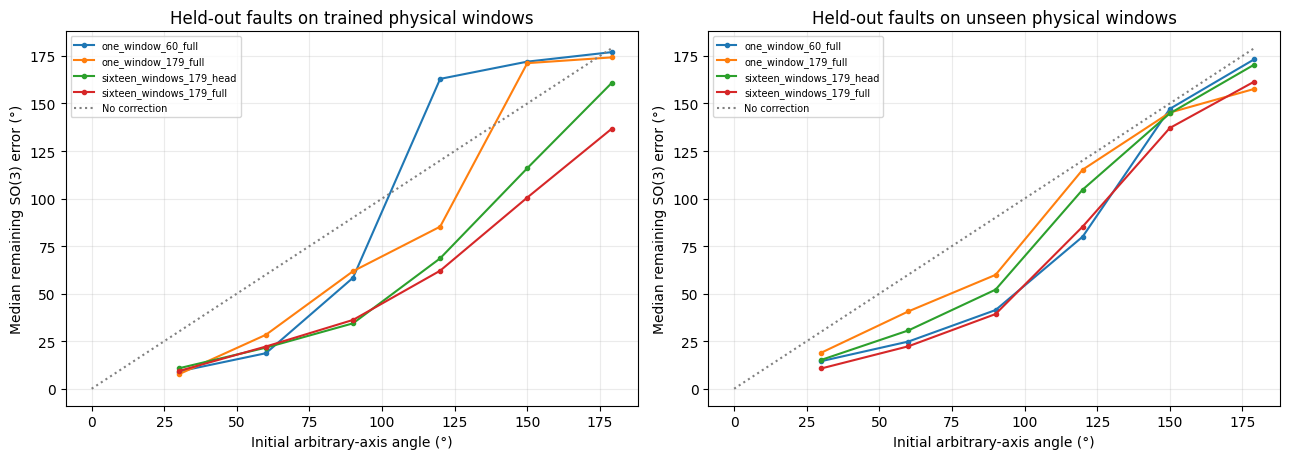

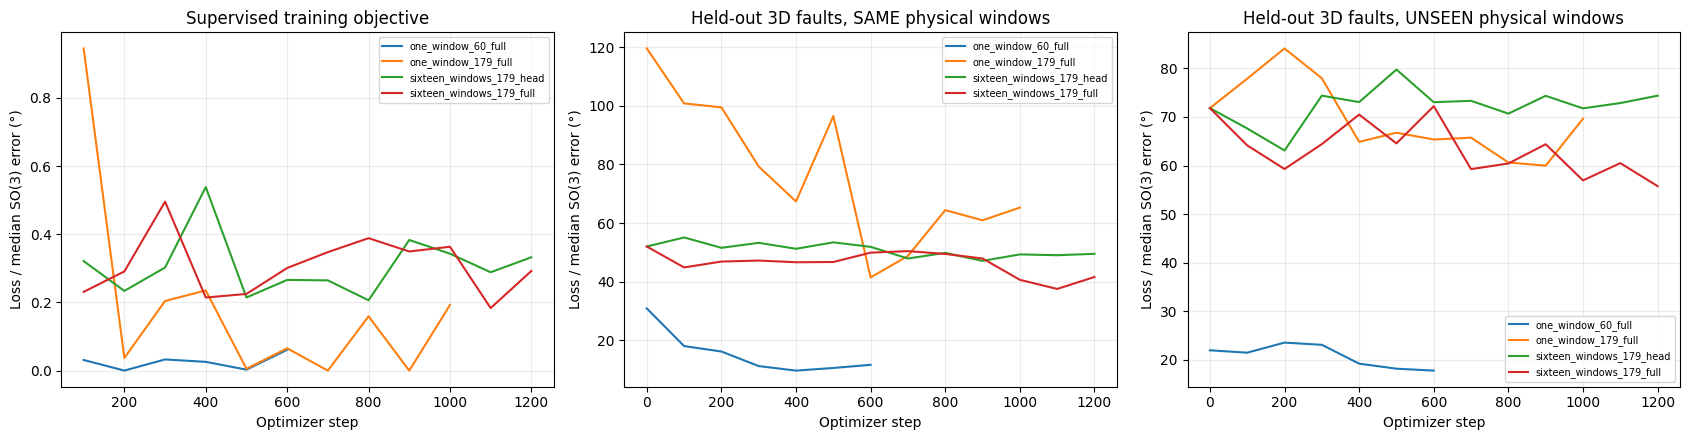

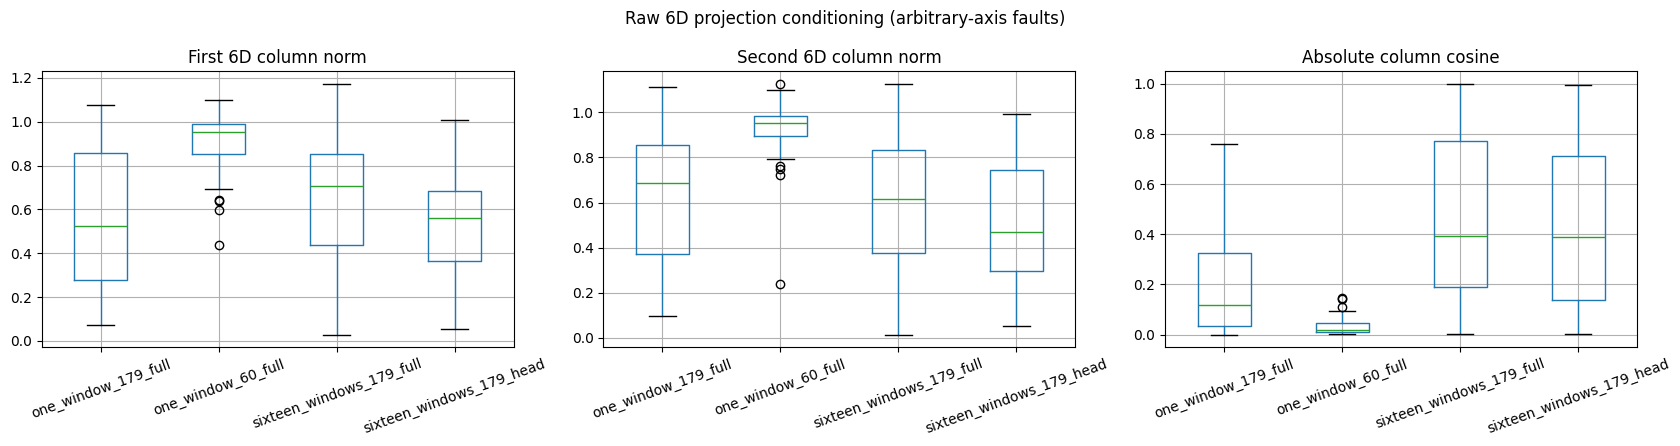

In [14]:
CAPACITY_DIR = RUN_DIR / 'capacity_diagnostics'

@torch.inference_mode()
def capacity_raw6d_metrics(candidate, cases):
    """Measure whether raw predicted 6D columns collapse or become collinear."""
    samples = []
    candidate.eval()
    for case in cases:
        if case['axis_type'] != 'arbitrary' or case['angle_deg'] == 0:
            continue
        output = model_predictions(case['window'], model_override=candidate).predictions[case['fault_key']]
        six = output.rotation_6d.reshape(-1, 2, 3)
        first, second = six[:, 0], six[:, 1]
        n1, n2 = first.norm(dim=-1), second.norm(dim=-1)
        collinearity = (first * second).sum(-1).abs() / (n1 * n2).clamp_min(1e-8)
        for i in range(len(n1)):
            samples.append(dict(angle_deg=case['angle_deg'], norm1=float(n1[i]), norm2=float(n2[i]), abs_collinearity=float(collinearity[i])))
    return pd.DataFrame(samples)

if RUN_CAPACITY_TEST:
    CAPACITY_DIR.mkdir(parents=True, exist_ok=True)
    capacity_physical, capacity_indices = fixed_physical_train_windows(16, TRAIN_AUG_SEED + 6_250_100)
    capacity_val_bank = build_probe_bank(val_dataset, n_windows=16, batch_size=8, seed=PROBE_SEED + 625, angles=(0., 30., 60., 90., 120., 150., 179.), n_sphere_directions=3)
    source_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    source_training, source_cpu_rng = model.training, torch.get_rng_state().clone()
    source_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    source_np_rng, source_py_rng = np.random.get_state(), random.getstate()
    capacity_rows, capacity_final_rows, capacity_six_rows, capacity_angle_rows = [], [], [], []
    try:
        for condition_id, setting in enumerate(CAPACITY_CONDITIONS):
            model.load_state_dict(source_state, strict=True)
            model.requires_grad_(True)
            model.train()
            if setting['trainable'] == 'head_only':
                model.requires_grad_(False)
                model.head_6d.requires_grad_(True)
            if setting['windows'] == 1:
                # Reconstruct a truly single-window physical batch to avoid wrong batch slicing.
                physical, indices = fixed_physical_train_windows(1, TRAIN_AUG_SEED + 6_250_100)
            else:
                physical, indices = capacity_physical, capacity_indices
            heldout_cases = build_physical_probe_bank(physical, indices, seed=PROBE_SEED + 629, angles=(0., 30., 60., 90., 120., 150., 179.), n_sphere_directions=3)
            stage = dict(name=setting['name'], cartesian_probability=0.0, arbitrary_max_deg=setting['max_deg'])
            params = [p for p in model.parameters() if p.requires_grad]
            if setting['trainable'] == 'head_only':
                cap_optimizer = torch.optim.AdamW(params, lr=CAPACITY_LR_HEAD, weight_decay=WEIGHT_DECAY)
            else:
                cap_optimizer = torch.optim.AdamW(parameter_groups(model, transformer_lr=CAPACITY_LR_TRANSFORMER, other_lr=CAPACITY_LR_HEAD), weight_decay=WEIGHT_DECAY)
            cap_gen = augmentation_generator(TRAIN_AUG_SEED + 6_260_000 + condition_id * 1000)
            for step in range(setting['steps'] + 1):
                if step:
                    model.train()
                    cap_optimizer.zero_grad(set_to_none=True)
                    batch = make_training_window(generator=cap_gen, physical_window=physical, stage=stage)
                    out = model_predictions(batch)
                    loss, _ = compute_6d_objective(batch, out)
                    if not bool(torch.isfinite(loss)):
                        raise FloatingPointError(f'Nonfinite capacity loss {setting["name"]}, step {step}')
                    loss.backward()
                    grad_norm = torch.nn.utils.clip_grad_norm_(params, GRADIENT_CLIP_NORM)
                    if not bool(torch.isfinite(grad_norm)):
                        raise FloatingPointError(f'Nonfinite capacity gradients {setting["name"]}, step {step}')
                    cap_optimizer.step()
                    train_loss = float(loss.detach())
                    del batch, out, loss
                else:
                    train_loss = np.nan
                if step == 0 or step % CAPACITY_REPORT_EVERY == 0 or step == setting['steps']:
                    same = evaluate_probe_bank(model, heldout_cases, name='same_physical_new_faults')
                    unseen = evaluate_probe_bank(model, capacity_val_bank, name='unseen_physical')
                    # Capacity cases focus on arbitrary axis and on the trained angular range.
                    def active_median(data):
                        subset = data[(data.axis_type == 'arbitrary') & (data.angle_deg > 0) & (data.angle_deg <= setting['max_deg'])]
                        return float(subset.after_deg.median()), float(subset.relative_remaining.mean())
                    same_median, same_ratio = active_median(same)
                    unseen_median, unseen_ratio = active_median(unseen)
                    row = dict(condition=setting['name'], step=step, train_loss=train_loss, same_median_deg=same_median, same_ratio=same_ratio, unseen_median_deg=unseen_median, unseen_ratio=unseen_ratio)
                    capacity_rows.append(row)
                    if step == 0 or step == setting['steps']:
                        for origin, results in (('same_physical', same), ('unseen_physical', unseen)):
                            subset = results[(results.axis_type == 'arbitrary') & (results.angle_deg > 0)]
                            for angle, values in subset.groupby('angle_deg'):
                                capacity_angle_rows.append(dict(condition=setting['name'], step=step, origin=origin, angle_deg=float(angle), median_after_deg=float(values.after_deg.median()), mean_after_deg=float(values.after_deg.mean()), mean_ratio=float(values.relative_remaining.mean())))
                    print(f'capacity {setting["name"]:25s} step {step:4d}/{setting["steps"]} | train={train_loss:.4f} | new axes on same windows={same_median:.2f}° | unseen windows={unseen_median:.2f}°', flush=True)
                    if step == setting['steps']:
                        capacity_final_rows.append(row)
                        six_metrics = capacity_raw6d_metrics(model, [case for case in heldout_cases if case['angle_deg'] in (60., 120., 179.)])
                        six_metrics['condition'] = setting['name']
                        capacity_six_rows.extend(six_metrics.to_dict('records'))
            del cap_optimizer
    finally:
        model.load_state_dict(source_state, strict=True)
        model.requires_grad_(True)
        model.train(source_training)
        model.zero_grad(set_to_none=True)
        torch.set_rng_state(source_cpu_rng)
        if source_cuda_rng is not None:
            torch.cuda.set_rng_state_all(source_cuda_rng)
        np.random.set_state(source_np_rng)
        random.setstate(source_py_rng)
        del source_state
        print('Capacity runs restored the original complete 002.30 model and RNG.')
    cap_df = pd.DataFrame(capacity_rows)
    cap_df.to_csv(CAPACITY_DIR / 'capacity_history.csv', index=False)
    cap_final = pd.DataFrame(capacity_final_rows)
    display(cap_final.round(3))
    if capacity_angle_rows:
        angle_df = pd.DataFrame(capacity_angle_rows)
        angle_df.to_csv(CAPACITY_DIR / 'capacity_angle_sweep.csv', index=False)
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
        for (condition, origin), values in angle_df.groupby(['condition', 'origin'], sort=False):
            last_step = values.step.max()
            final_values = values[values.step == last_step].sort_values('angle_deg')
            ax = axes[0 if origin == 'same_physical' else 1]
            ax.plot(final_values.angle_deg, final_values.median_after_deg, '-o', markersize=3, label=condition)
        for ax, title in zip(axes, ('Held-out faults on trained physical windows', 'Held-out faults on unseen physical windows')):
            ax.plot([0, 179], [0, 179], linestyle=':', color='gray', label='No correction')
            ax.set(xlabel='Initial arbitrary-axis angle (°)', ylabel='Median remaining SO(3) error (°)', title=title)
            ax.grid(alpha=.25)
            ax.legend(fontsize=7)
        fig.tight_layout()
        fig.savefig(CAPACITY_DIR / 'capacity_by_angle.png', dpi=175)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)
    if capacity_six_rows:
        six_df = pd.DataFrame(capacity_six_rows)
        six_df.to_csv(CAPACITY_DIR / 'raw_6d_conditioning.csv', index=False)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for name, part in cap_df.groupby('condition', sort=False):
        axes[0].plot(part.step, part.train_loss, label=name)
        axes[1].plot(part.step, part.same_median_deg, label=name)
        axes[2].plot(part.step, part.unseen_median_deg, label=name)
    for ax, title in zip(axes, ('Supervised training objective', 'Held-out 3D faults, SAME physical windows', 'Held-out 3D faults, UNSEEN physical windows')):
        ax.set(xlabel='Optimizer step', ylabel='Loss / median SO(3) error (°)', title=title)
        ax.grid(alpha=.25)
        ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(CAPACITY_DIR / 'capacity_learning_curves.png', dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    if capacity_six_rows:
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
        six_df.boxplot(column='norm1', by='condition', ax=axes[0], rot=20)
        six_df.boxplot(column='norm2', by='condition', ax=axes[1], rot=20)
        six_df.boxplot(column='abs_collinearity', by='condition', ax=axes[2], rot=20)
        for ax, title in zip(axes, ('First 6D column norm', 'Second 6D column norm', 'Absolute column cosine')):
            ax.set_title(title)
            ax.set_xlabel('')
        fig.suptitle('Raw 6D projection conditioning (arbitrary-axis faults)')
        fig.tight_layout()
        fig.savefig(CAPACITY_DIR / 'raw_6d_conditioning.png', dpi=180)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)
else:
    print('Capacity diagnostic disabled. Enable RUN_CAPACITY_TEST to test one vs 16 windows and head-only vs full model.')

## 10. Full training with stage transitions and exact resume

This is a **new 002.32 run** from the complete `002.30/best.pt` model (or optional final stochastic stage-best weights). Epochs 1–12 train stage A; epochs 13–32 stage B; later epochs stage C. No model or AdamW reset at stage transitions. The scheduler is reset **only** on a stage change, so stage A's low-angle score does not cause premature LR decay during B/C. AdamW moments are continuous. Checkpoints are selected on a fixed full-range score; scheduler monitors the stage-appropriate score. `last.pt` restores optimizer, scheduler, generators and current epoch, and the stage is recomputed deterministically from the epoch. Never resume old `002.31/last.pt` into this distribution.


In [15]:
def run_6d_epoch(loader, *, training, generator, stage, max_batches=None):
    model.train(training)
    sums, counts = defaultdict(float), defaultdict(float)
    n_samples, optimizer_updates = 0, 0
    pending_samples, pending_microbatches = 0, 0
    started = time.perf_counter()
    if training:
        optimizer.zero_grad(set_to_none=True)

    def optimizer_flush():
        nonlocal pending_samples, pending_microbatches, optimizer_updates
        if pending_samples == 0:
            return
        for p in model.parameters():
            if p.grad is not None:
                p.grad.div_(pending_samples)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        optimizer_updates += 1
        pending_samples, pending_microbatches = 0, 0

    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_id, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_id >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            augmented = make_training_window(base, generator=generator, stage=stage)
            prediction = model_predictions(augmented)
            loss, metrics = compute_6d_objective(augmented, prediction)
            n = len(next(iter(augmented.current_calibration.values())).transform)
            if training:
                (loss * n).backward()
                pending_samples += n
                pending_microbatches += 1
                if pending_microbatches >= GRADIENT_ACCUMULATION_STEPS:
                    optimizer_flush()
            for key, value in metrics.items():
                if key == 'active_rotation_count':
                    continue
                sums[key] += float(value) * n
                counts[key] += n
            n_samples += n
            del base, augmented, prediction, loss
        if training:
            optimizer_flush()
    if not n_samples:
        raise RuntimeError('Epoch used no samples')
    result = metric_average(sums, counts)
    result.update(n_samples=n_samples, optimizer_updates=optimizer_updates, elapsed_s=time.perf_counter()-started)

    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result


In [16]:
BEST_CHECKPOINT_PATH = RUN_DIR / 'best.pt'
LAST_CHECKPOINT_PATH = RUN_DIR / 'last.pt'
HISTORY_PATH = RUN_DIR / 'training_6d_history.csv'
PAIR_HISTORY_PATH = RUN_DIR / 'probe_sensor_direction_history.csv'
FULL_INIT_PATH = PREFLIGHT_BEST_PATH if FULL_INIT_FROM_PREFLIGHT_BEST else SOURCE_230_PATH

full_probe_bank = build_probe_bank(val_dataset, n_windows=FULL_PROBE_WINDOWS, batch_size=FULL_PROBE_BATCH_SIZE, seed=PROBE_SEED, angles=PROBE_ANGLES_DEG, n_sphere_directions=FULL_PROBE_3D_DIRECTIONS)
optimizer = torch.optim.AdamW(parameter_groups(model), weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_PROBES)
train_generator = augmentation_generator(TRAIN_AUG_SEED + 61_000)
start_epoch, global_step, best_score, best_epoch = 0, 0, float('inf'), 0
history, pair_history = [], []

checkpoint_config = dict(
    run_name=RUN_NAME, source_checkpoint=str(SOURCE_230_PATH), full_init_checkpoint=str(FULL_INIT_PATH),
    architecture='PooledCalibration6DModel', calibration_keys=tuple(CALIBRATION_KEYS), train_names=tuple(TRAIN_NAMES), val_names=tuple(VAL_NAMES),
    curriculum_stages=tuple((s['name'], s['cartesian_probability'], s['arbitrary_max_deg']) for s in CURRICULUM_STAGES), full_stage_end_epochs=tuple(FULL_STAGE_END_EPOCHS),
    fine_max_deg=FINE_ROTATION_MAX_DEG, fine_scale_deg=FINE_ROTATION_SCALE_DEG, coarse_range_deg=(COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), coarse_probability=COARSE_PRIOR_PROBABILITY,
    identity_probability=IDENTITY_PROBABILITY, one_faulted_sensor=True, arbitrary_axis_isotropic=True,
    randomize_true_sensor_frames=RANDOMIZE_TRUE_SENSOR_FRAMES, true_rotation_max_rad=TRUE_CALIBRATION_ROTATION_MAX_RAD,
    loss_weights=asdict(LOSS_WEIGHTS), active_weight=ACTIVE_ROTATION_SUPERVISION_WEIGHT,
    train_batch_size=TRAIN_BATCH_SIZE, gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    transformer_lr=TRANSFORMER_LR, head_mlp_lr=HEAD_MLP_LR, weight_decay=WEIGHT_DECAY,
    scheduler='ReduceLROnPlateau(stage_probe)', lr_reduce_factor=LR_REDUCE_FACTOR, lr_patience_probes=LR_PATIENCE_PROBES,
    probe_angles=PROBE_ANGLES_DEG, probe_score_angles=PROBE_SCORE_ANGLES_DEG, probe_seed=PROBE_SEED,
    probe_cartesian_score_weight=PROBE_CARTESIAN_SCORE_WEIGHT,
    probe_windows=FULL_PROBE_WINDOWS, probe_3d_directions=FULL_PROBE_3D_DIRECTIONS,
    probe_every_epochs=PROBE_EVERY_EPOCHS, worst_pair_weight=WORST_PAIR_WEIGHT,
    near_pi_weight=NEAR_PI_WEIGHT, zero_drift_weight=ZERO_DRIFT_WEIGHT, tau_reference_s=dict(REFINED_TAU_BY_SENSOR_S),
)

def save_61_checkpoint(path, epoch_number, metrics):
    save_training_checkpoint(path, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch_number, global_step=global_step,
                             metrics=metrics, generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator},
                             extra_state={'config_6d': checkpoint_config, 'best_probe_score': best_score, 'best_epoch': best_epoch})

if RUN_FULL_TRAINING:
    if RESUME_FULL_TRAINING:
        if not LAST_CHECKPOINT_PATH.is_file():
            raise FileNotFoundError(f'No NEW curriculum last.pt for resume: {LAST_CHECKPOINT_PATH}')
        raw = torch.load(LAST_CHECKPOINT_PATH, map_location='cpu', weights_only=False)  # Trusted local checkpoint only.
        saved_cfg = (raw.get('extra_state') or {}).get('config_6d')
        if saved_cfg != checkpoint_config:
            differences = {k: ((saved_cfg or {}).get(k, '<missing>'), checkpoint_config.get(k, '<missing>')) for k in set(saved_cfg or {}) | set(checkpoint_config) if (saved_cfg or {}).get(k, '<missing>') != checkpoint_config.get(k, '<missing>')}
            raise RuntimeError(f'Changed curriculum settings; create a NEW run instead: {differences}')
        best_score = float(raw['extra_state']['best_probe_score'])
        best_epoch = int(raw['extra_state']['best_epoch'])
        del raw
        loaded = load_training_checkpoint(LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler, generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator}, map_location=DEVICE, restore_rng_state=True)
        start_epoch, global_step = int(loaded['epoch']), int(loaded['global_step'])
        if not optimizer.state:
            raise RuntimeError('AdamW was not restored')
        if not HISTORY_PATH.is_file():
            raise FileNotFoundError(f'Missing resume history {HISTORY_PATH}')
        frame = pd.read_csv(HISTORY_PATH).query('epoch <= @start_epoch')
        if frame.empty or int(frame.epoch.iloc[-1]) != start_epoch:
            raise RuntimeError('Resume history does not end at the saved epoch')
        history = frame.to_dict('records')
        if PAIR_HISTORY_PATH.is_file():
            pair_frame = pd.read_csv(PAIR_HISTORY_PATH)
            pair_history = pair_frame[pair_frame.epoch <= start_epoch].to_dict('records')
        if FULL_TARGET_EPOCHS <= start_epoch:
            raise ValueError(f'Target total epochs {FULL_TARGET_EPOCHS} must exceed completed epochs {start_epoch}')
        print(f'RESUMED 002.32 epoch={start_epoch}, next stage={curriculum_stage_for_epoch(start_epoch)["name"]}, target={FULL_TARGET_EPOCHS}, AdamW entries={len(optimizer.state)}')
        del loaded
    else:
        if any(path.is_file() for path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH)):
            raise FileExistsError(f'New curriculum run already contains checkpoints: {RUN_DIR}; enable RESUME_FULL_TRAINING or change RUN_NAME')
        if FULL_INIT_FROM_PREFLIGHT_BEST:
            if not FULL_INIT_PATH.is_file():
                raise FileNotFoundError(FULL_INIT_PATH)
            raw = torch.load(FULL_INIT_PATH, map_location='cpu', weights_only=True)
            model.load_state_dict(raw['model_state_dict'], strict=True)
            del raw
        else:
            load_training_checkpoint(SOURCE_230_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
        initial_frame = evaluate_probe_bank(model, full_probe_bank, name='initial_curriculum')
        initial_metrics, _ = probe_metrics(initial_frame)
        best_score, best_epoch = initial_metrics['score'], 0
        save_61_checkpoint(BEST_CHECKPOINT_PATH, 0, dict(probe_score=best_score, initial=True))
        print('NEW 002.32 run, complete model:', FULL_INIT_PATH, '| new AdamW; initial balanced score:', round(best_score, 5))
else:
    print('Full training disabled. Preflight and capacity experiments do not change full-run initialization.')


NEW 002.32 run, complete model: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/best.pt | new AdamW; initial balanced score: 0.75364


# Diagnostics

In [17]:
# Appendix 14A: Shared setup for gradient-interference and feature-separability diagnostics.
# Run after Notebook 61's model, sampling, and probe-helper cells. No training run is needed.
import copy
from itertools import combinations

DIAG61_CHECKPOINT = SOURCE_230_PATH  # Alternatively, a Notebook 61 best.pt or last.pt.
DIAG61_DIR = RUN_DIR / 'plots' / 'angle_interference_and_features'
DIAG61_DIR.mkdir(parents=True, exist_ok=True)
DIAG61_WINDOWS = 4                       # Increase to 8 or 16 for more reliable results.
DIAG61_ANGLES = (30.0, 90.0, 150.0, 179.0)
DIAG61_KEYS = tuple(CALIBRATION_KEYS)    # Can restrict to ('lidar',) for a quick check.
DIAG61_DIRECTION_VECTORS = {
    'X': (1.0, 0.0, 0.0),
    'U1': (0.5773502692, 0.5773502692, 0.5773502692),
}
DIAG61_SIGNS = (1, -1)
DIAG61_OBJECTIVE = 'full'                # 'full' = Notebook 61 exact loss; 'active_only' = control.
DIAG61_SEED = TRAIN_AUG_SEED + 6_310_000

# The diagnostic is intentionally independent of the possibly modified 'model' in the kernel.
diag61_net = copy.deepcopy(model).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(DIAG61_CHECKPOINT, model=diag61_net, map_location=DEVICE, restore_rng_state=False)
diag61_net.requires_grad_(True)
diag61_net.eval()                         # No dropout or mutable batch-norm statistics.

diag61_physical, diag61_indices = fixed_physical_train_windows(DIAG61_WINDOWS, DIAG61_SEED)
diag61_n = len(diag61_indices)
diag61_cases = {angle: [] for angle in DIAG61_ANGLES}

for diag61_angle in DIAG61_ANGLES:
    for diag61_key in DIAG61_KEYS:
        for diag61_axis, diag61_direction in DIAG61_DIRECTION_VECTORS.items():
            direction = torch.tensor(diag61_direction, dtype=DTYPE, device=DEVICE)
            direction = direction / direction.norm()
            for diag61_sign in DIAG61_SIGNS:
                xi = {key: torch.zeros(diag61_n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                xi[diag61_key][:, :3] = diag61_sign * np.deg2rad(diag61_angle) * direction[None, :]
                prior = apply_independent_prior_faults(diag61_physical.current_calibration, xi)
                window = clone_with_current_calibration(diag61_physical, prior)
                measured = rotation_geodesic_deg(window.current_calibration[diag61_key].transform[:, :3, :3], window.targets[diag61_key].next_transform[:, :3, :3])
                assert bool(torch.allclose(measured, measured.new_full(measured.shape, diag61_angle), atol=0.08, rtol=0))
                diag61_cases[diag61_angle].append(dict(window=window, key=diag61_key, axis=diag61_axis, sign=diag61_sign, angle_deg=diag61_angle))


def diag61_loss(candidate, case):
    """Return the exact training objective or the isolated faulted-sensor 6D control."""
    window = case['window']
    output = model_predictions(window, model_override=candidate)
    if DIAG61_OBJECTIVE == 'full':
        loss, _ = compute_6d_objective(window, output)
    elif DIAG61_OBJECTIVE == 'active_only':
        key = case['key']
        prior_R = window.current_calibration[key].transform[:, :3, :3]
        gt_R = window.targets[key].next_transform[:, :3, :3]
        required_R = gt_R @ prior_R.transpose(-1, -2)
        loss = LOSS_WEIGHTS.rotation_weight * LOSS_WEIGHTS.rotation_6d_weight * (output.predictions[key].rotation_6d - matrix_to_rotation_6d(required_R)).square().mean()
    else:
        raise ValueError(f'Unknown diagnostic objective: {DIAG61_OBJECTIVE}')
    return loss, output


def diag61_parameters(candidate):
    """Block partitions use the actual Notebook 61 module names and preserve parameter order."""
    return {
        'Transformer': tuple(candidate.transformer_encoder.parameters()),
        'Pooler': tuple(candidate.pooler.parameters()),
        'Shared MLP': tuple(candidate.mlp_body.parameters()),
        '6D head': tuple(candidate.head_6d.parameters()),
    }

assert len(diag61_cases[DIAG61_ANGLES[0]]) == len(DIAG61_KEYS) * len(DIAG61_DIRECTION_VECTORS) * len(DIAG61_SIGNS)
assert sum(p.numel() for block in diag61_parameters(diag61_net).values() for p in block) == sum(p.numel() for p in diag61_net.parameters())
print('Diagnostics checkpoint:', DIAG61_CHECKPOINT)
print('Matched physical windows:', diag61_n, '| faults per angle:', len(diag61_cases[DIAG61_ANGLES[0]]))
print('Angles:', DIAG61_ANGLES, '| keys:', DIAG61_KEYS, '| loss:', DIAG61_OBJECTIVE)
print('Output directory:', DIAG61_DIR)


Diagnostics checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/best.pt
Matched physical windows: 4 | faults per angle: 12
Angles: (30.0, 90.0, 150.0, 179.0) | keys: ('imu', 'lidar', 'lidar_right') | loss: full
Output directory: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.31_curriculum_cartesian_arbitrary/plots/angle_interference_and_features


Gradient group 30° complete (12 matched cases)
Gradient group 90° complete (12 matched cases)
Gradient group 150° complete (12 matched cases)
Gradient group 179° complete (12 matched cases)


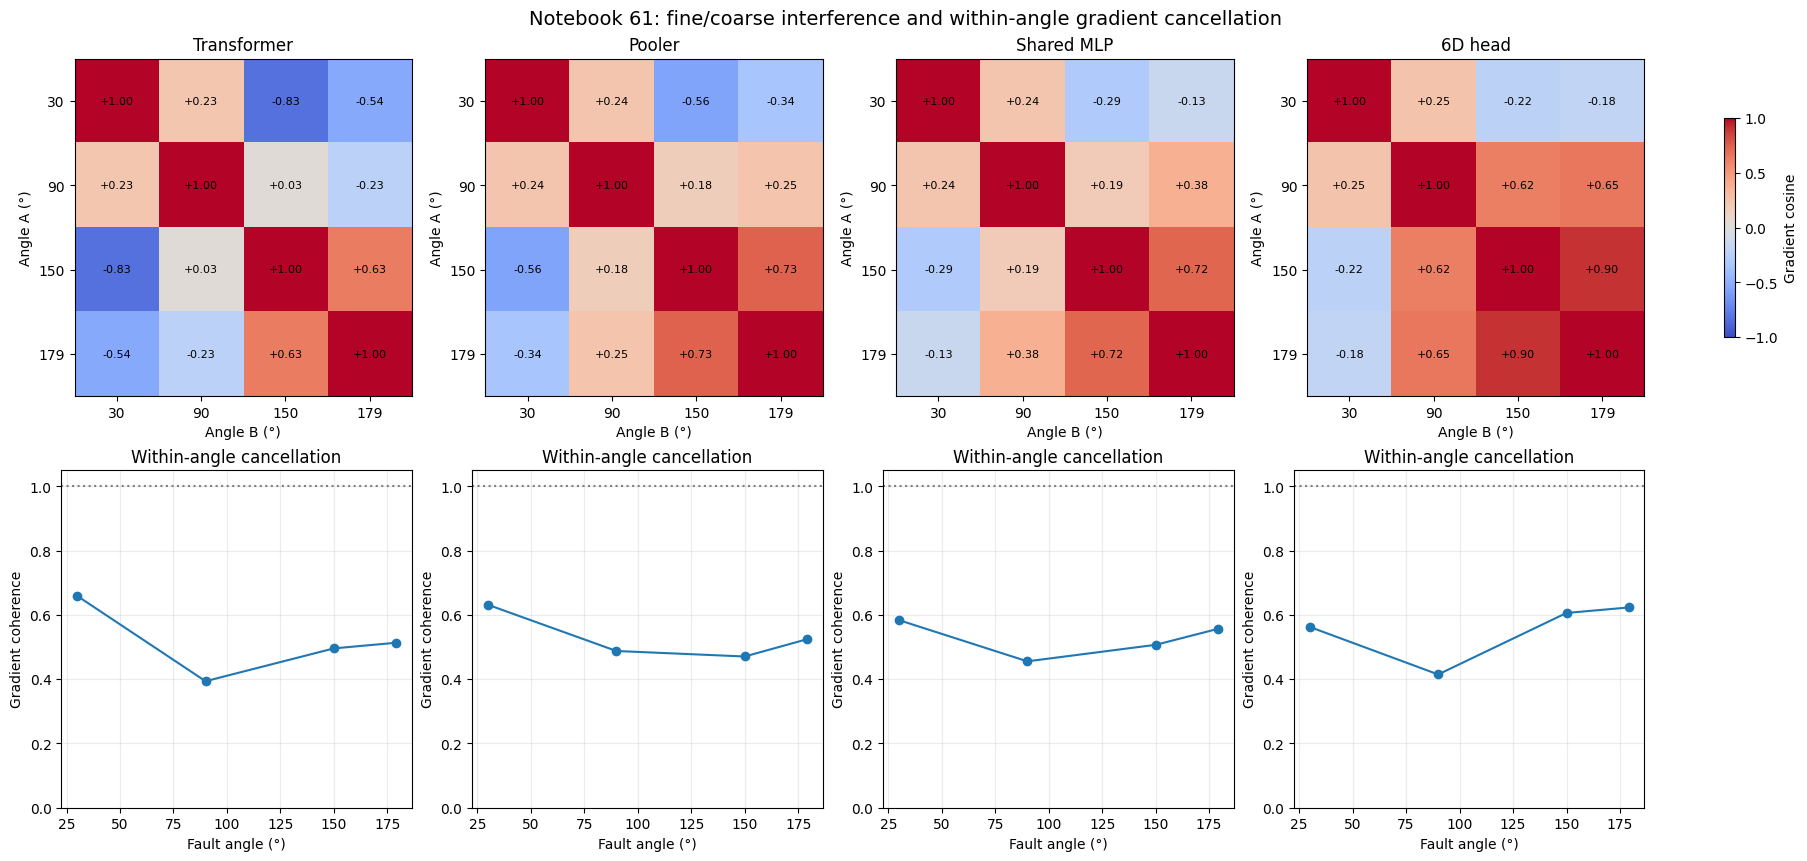

,angle_deg,block,mean_gradient_norm,mean_case_gradient_norm,coherence,n_cases
0,30.0,Transformer,8.0873,12.2665,0.6593,12
1,30.0,Pooler,0.5525,0.8748,0.6316,12
2,30.0,Shared MLP,0.2515,0.4306,0.5840,12
3,30.0,6D head,0.5570,0.9899,0.5627,12
4,90.0,Transformer,4.4717,11.3541,0.3938,12
5,90.0,Pooler,0.3532,0.7240,0.4879,12
6,90.0,Shared MLP,0.3397,0.7455,0.4557,12
7,90.0,6D head,1.4013,3.3775,0.4149,12
8,150.0,Transformer,5.8048,11.7032,0.4960,12
9,150.0,Pooler,0.5443,1.1563,0.4708,12


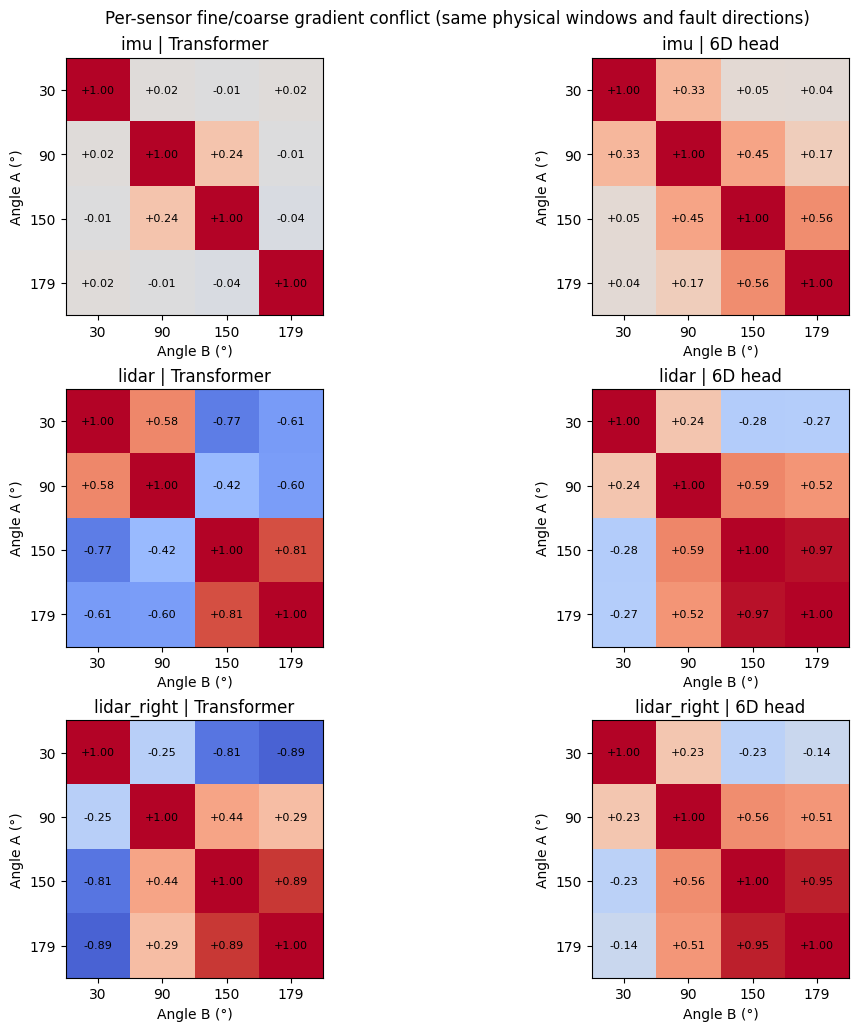

In [18]:
# Appendix 14B: Parameter gradients and within-angle gradient cancellation.
# No optimizer steps, no updates to 'model', and no mutation of its gradients.

diag61_blocks = diag61_parameters(diag61_net)
diag61_flat_parameters = [p for block in diag61_blocks.values() for p in block]
diag61_grads = {}
diag61_key_grads = {key: {} for key in DIAG61_KEYS}
diag61_gradient_rows = []

for angle in DIAG61_ANGLES:
    block_sums = {name: None for name in diag61_blocks}
    block_individual_norms = {name: [] for name in diag61_blocks}
    block_per_case = {name: [] for name in diag61_blocks}
    key_block_sums = {key: {name: None for name in diag61_blocks} for key in DIAG61_KEYS}
    key_counts = {key: 0 for key in DIAG61_KEYS}
    for case in diag61_cases[angle]:
        key_counts[case['key']] += 1
        loss, output = diag61_loss(diag61_net, case)
        gradients = torch.autograd.grad(loss, diag61_flat_parameters, allow_unused=True)
        cursor = 0
        for name, parameters in diag61_blocks.items():
            pieces = []
            for param in parameters:
                grad = gradients[cursor]
                cursor += 1
                pieces.append((torch.zeros_like(param) if grad is None else grad).detach().reshape(-1).cpu())
            vec = torch.cat(pieces)
            assert bool(torch.isfinite(vec).all()), (name, angle)
            block_sums[name] = vec.clone() if block_sums[name] is None else block_sums[name] + vec
            block_individual_norms[name].append(float(vec.norm()))
            block_per_case[name].append(vec)
            previous = key_block_sums[case['key']][name]
            key_block_sums[case['key']][name] = vec.clone() if previous is None else previous + vec
        del loss, output, gradients

    diag61_grads[angle] = {}
    for key in DIAG61_KEYS:
        diag61_key_grads[key][angle] = {name: key_block_sums[key][name] / key_counts[key] for name in diag61_blocks}
    for name in diag61_blocks:
        averaged = block_sums[name] / len(diag61_cases[angle])
        diag61_grads[angle][name] = averaged
        individual_mean = float(np.mean(block_individual_norms[name]))
        coherence = float(averaged.norm()) / max(individual_mean, 1e-12)
        # Coherence near 0 means strong cancellation across sensor/axis/sign cases.
        diag61_gradient_rows.append(dict(angle_deg=angle, block=name, mean_gradient_norm=float(averaged.norm()), mean_case_gradient_norm=individual_mean, coherence=coherence, n_cases=len(diag61_cases[angle])))
    print(f'Gradient group {angle:g}° complete ({len(diag61_cases[angle])} matched cases)', flush=True)

diag61_grad_df = pd.DataFrame(diag61_gradient_rows)
diag61_grad_df.to_csv(DIAG61_DIR / 'gradient_norms_and_coherence.csv', index=False)
diag61_cosines = {}
for name in diag61_blocks:
    vectors = [diag61_grads[angle][name] for angle in DIAG61_ANGLES]
    norms = [float(vec.norm()) for vec in vectors]
    diag61_cosines[name] = np.array([[float(torch.dot(a, b)) / max(norms[i] * norms[j], 1e-12) for j, b in enumerate(vectors)] for i, a in enumerate(vectors)])
    pd.DataFrame(diag61_cosines[name], index=DIAG61_ANGLES, columns=DIAG61_ANGLES).to_csv(DIAG61_DIR / f'gradient_cosine_{name.lower().replace(" ", "_")}.csv')

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), constrained_layout=True)
for j, name in enumerate(diag61_blocks):
    ax = axes[0, j]
    im = ax.imshow(diag61_cosines[name], vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(DIAG61_ANGLES)), [f'{a:g}' for a in DIAG61_ANGLES])
    ax.set_yticks(range(len(DIAG61_ANGLES)), [f'{a:g}' for a in DIAG61_ANGLES])
    ax.set(title=name, xlabel='Angle B (°)', ylabel='Angle A (°)')
    for row in range(len(DIAG61_ANGLES)):
        for col in range(len(DIAG61_ANGLES)):
            ax.text(col, row, f'{diag61_cosines[name][row, col]:+.2f}', ha='center', va='center', fontsize=8)
    values = diag61_grad_df.loc[diag61_grad_df.block == name].sort_values('angle_deg')
    ax = axes[1, j]
    ax.plot(values.angle_deg, values.coherence, '-o', label='||mean g|| / mean ||g||')
    ax.axhline(1.0, linestyle=':', color='gray')
    ax.set(xlabel='Fault angle (°)', ylabel='Gradient coherence', title='Within-angle cancellation', ylim=(0, 1.05))
    ax.grid(alpha=0.25)
fig.colorbar(im, ax=axes[0, :], shrink=0.65, label='Gradient cosine')
fig.suptitle('Notebook 61: fine/coarse interference and within-angle gradient cancellation', fontsize=14)
fig.savefig(DIAG61_DIR / 'gradient_conflict_heatmaps.png', dpi=170)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
display(diag61_grad_df.round(4))

# Same comparison separately for each sensor: global averaging can hide task-specific conflict.
fig, axes = plt.subplots(len(DIAG61_KEYS), 2, figsize=(10.5, 3.4 * len(DIAG61_KEYS)), squeeze=False, constrained_layout=True)
for i, key in enumerate(DIAG61_KEYS):
    for j, block in enumerate(('Transformer', '6D head')):
        vectors = [diag61_key_grads[key][angle][block] for angle in DIAG61_ANGLES]
        norms = [max(float(v.norm()), 1e-12) for v in vectors]
        matrix = np.array([[float(torch.dot(a, b)) / (norms[k] * norms[l]) for l, b in enumerate(vectors)] for k, a in enumerate(vectors)])
        ax = axes[i, j]
        ax.imshow(matrix, vmin=-1, vmax=1, cmap='coolwarm')
        ax.set_xticks(range(len(DIAG61_ANGLES)), [f'{a:g}' for a in DIAG61_ANGLES])
        ax.set_yticks(range(len(DIAG61_ANGLES)), [f'{a:g}' for a in DIAG61_ANGLES])
        ax.set(title=f'{key} | {block}', xlabel='Angle B (°)', ylabel='Angle A (°)')
        for k in range(len(DIAG61_ANGLES)):
            for l in range(len(DIAG61_ANGLES)):
                ax.text(l, k, f'{matrix[k,l]:+.2f}', ha='center', va='center', fontsize=8)
        pd.DataFrame(matrix, index=DIAG61_ANGLES, columns=DIAG61_ANGLES).to_csv(DIAG61_DIR / f'gradient_cosine_{key}_{block.lower().replace(" ", "_")}.csv')
fig.suptitle('Per-sensor fine/coarse gradient conflict (same physical windows and fault directions)')
fig.savefig(DIAG61_DIR / 'gradient_conflict_by_sensor.png', dpi=170)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)


AdamW train angle=30° step=1 preclip_grad=8.134
AdamW train angle=30° step=2 preclip_grad=7.028
AdamW train angle=30° step=3 preclip_grad=5.875
AdamW train angle=179° step=1 preclip_grad=10.346
AdamW train angle=179° step=2 preclip_grad=9.737
AdamW train angle=179° step=3 preclip_grad=9.493


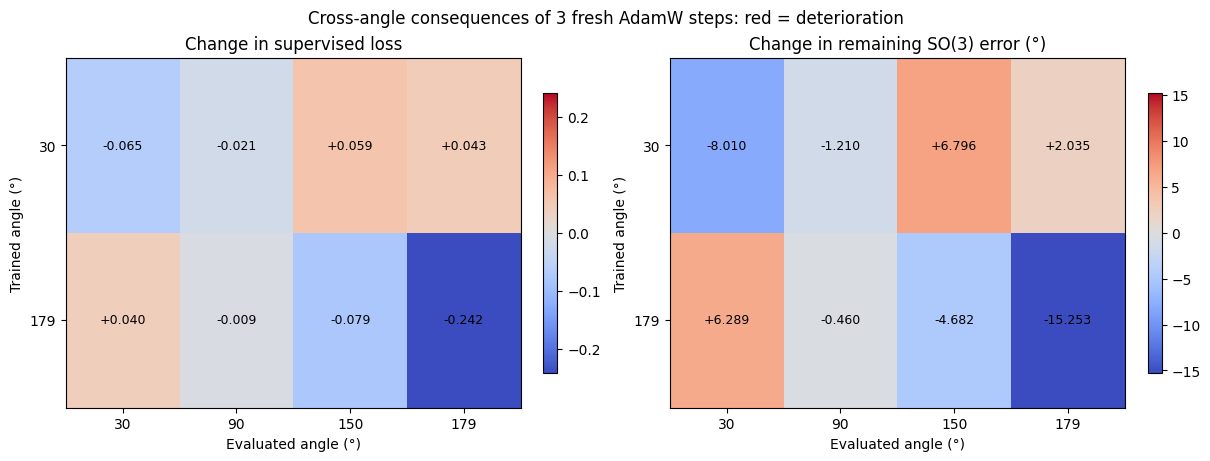

,train_angle_deg,eval_angle_deg,n_updates,loss_before,loss_after,delta_loss,residual_before_deg,residual_after_deg,delta_residual_deg
0,30.0,30.0,3,0.13756,0.07223,-0.06532,27.63740,19.62732,-8.01008
1,30.0,90.0,3,0.50471,0.48413,-0.02057,73.30955,72.09958,-1.20997
2,30.0,150.0,3,0.80797,0.86688,0.05891,106.19621,112.99212,6.79591
3,30.0,179.0,3,1.13081,1.17428,0.04347,154.33928,156.37456,2.03529
4,179.0,30.0,3,0.13756,0.17753,0.03997,27.63740,33.92638,6.28897
5,179.0,90.0,3,0.50471,0.49608,-0.00863,73.30955,72.84996,-0.45959
6,179.0,150.0,3,0.80797,0.72881,-0.07916,106.19621,101.51394,-4.68227
7,179.0,179.0,3,1.13081,0.88895,-0.24186,154.33928,139.08622,-15.25306


In [19]:
# Appendix 14C: Actual short AdamW updates. Train on one angle; measure effects on ALL angles.
# The source model/optimizer are untouched. Every row starts from the exact same checkpoint.
DIAG61_PROBE_TRAIN_ANGLES = (30.0, 179.0)
DIAG61_PROBE_STEPS = 3
DIAG61_PROBE_HEAD_LR = 1e-4
DIAG61_PROBE_TRANSFORMER_LR = 1e-5

@torch.no_grad()
def diag61_evaluate_all_angles(candidate):
    candidate.eval()
    results = {}
    for angle in DIAG61_ANGLES:
        losses, residuals = [], []
        for case in diag61_cases[angle]:
            loss, output = diag61_loss(candidate, case)
            key, window = case['key'], case['window']
            prior_R = window.current_calibration[key].transform[:, :3, :3]
            truth_R = window.targets[key].next_transform[:, :3, :3]
            corrected_R = output.predictions[key].delta_rotation @ prior_R
            losses.append(float(loss))
            residuals.extend(rotation_geodesic_deg(corrected_R, truth_R).cpu().tolist())
        results[angle] = dict(loss=float(np.mean(losses)), residual_deg=float(np.mean(residuals)))
    return results

diag61_probe_initial = diag61_evaluate_all_angles(diag61_net)
diag61_probe_rows = []
for train_angle in DIAG61_PROBE_TRAIN_ANGLES:
    candidate = copy.deepcopy(diag61_net)
    candidate.eval()  # deterministic forward; gradients still enabled
    opt = torch.optim.AdamW(parameter_groups(candidate, transformer_lr=DIAG61_PROBE_TRANSFORMER_LR, other_lr=DIAG61_PROBE_HEAD_LR), weight_decay=WEIGHT_DECAY)
    for step in range(1, DIAG61_PROBE_STEPS + 1):
        opt.zero_grad(set_to_none=True)
        for case in diag61_cases[train_angle]:
            loss, output = diag61_loss(candidate, case)
            (loss / len(diag61_cases[train_angle])).backward()
            del loss, output
        preclip_norm = torch.nn.utils.clip_grad_norm_(candidate.parameters(), GRADIENT_CLIP_NORM)
        opt.step()
        print(f'AdamW train angle={train_angle:g}° step={step} preclip_grad={float(preclip_norm):.3f}', flush=True)
    final_metrics = diag61_evaluate_all_angles(candidate)
    for eval_angle in DIAG61_ANGLES:
        old, new = diag61_probe_initial[eval_angle], final_metrics[eval_angle]
        diag61_probe_rows.append(dict(train_angle_deg=train_angle, eval_angle_deg=eval_angle, n_updates=DIAG61_PROBE_STEPS,
                                      loss_before=old['loss'], loss_after=new['loss'], delta_loss=new['loss'] - old['loss'],
                                      residual_before_deg=old['residual_deg'], residual_after_deg=new['residual_deg'],
                                      delta_residual_deg=new['residual_deg'] - old['residual_deg']))
    del candidate, opt

diag61_update_df = pd.DataFrame(diag61_probe_rows)
diag61_update_df.to_csv(DIAG61_DIR / 'adamw_cross_angle_changes.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, metric, label in zip(axes, ('delta_loss', 'delta_residual_deg'), ('Change in supervised loss', 'Change in remaining SO(3) error (°)')):
    table = diag61_update_df.pivot(index='train_angle_deg', columns='eval_angle_deg', values=metric).reindex(index=DIAG61_PROBE_TRAIN_ANGLES, columns=DIAG61_ANGLES)
    limit = max(float(np.abs(table.to_numpy()).max()), 1e-6)
    im = ax.imshow(table.to_numpy(), cmap='coolwarm', vmin=-limit, vmax=limit, aspect='auto')
    ax.set_xticks(range(len(table.columns)), [f'{x:g}' for x in table.columns])
    ax.set_yticks(range(len(table.index)), [f'{x:g}' for x in table.index])
    ax.set(xlabel='Evaluated angle (°)', ylabel='Trained angle (°)', title=label)
    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            ax.text(j, i, f'{table.iat[i, j]:+.3f}', ha='center', va='center', fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f'Cross-angle consequences of {DIAG61_PROBE_STEPS} fresh AdamW steps: red = deterioration')
fig.savefig(DIAG61_DIR / 'adamw_cross_angle_impact.png', dpi=170)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
display(diag61_update_df.round(5))


Feature cases complete: imu / 30° / 12 directions
Feature cases complete: imu / 90° / 12 directions
Feature cases complete: imu / 150° / 12 directions
Feature cases complete: imu / 179° / 12 directions
Feature cases complete: lidar / 30° / 12 directions
Feature cases complete: lidar / 90° / 12 directions
Feature cases complete: lidar / 150° / 12 directions
Feature cases complete: lidar / 179° / 12 directions
Feature cases complete: lidar_right / 30° / 12 directions
Feature cases complete: lidar_right / 90° / 12 directions
Feature cases complete: lidar_right / 150° / 12 directions
Feature cases complete: lidar_right / 179° / 12 directions


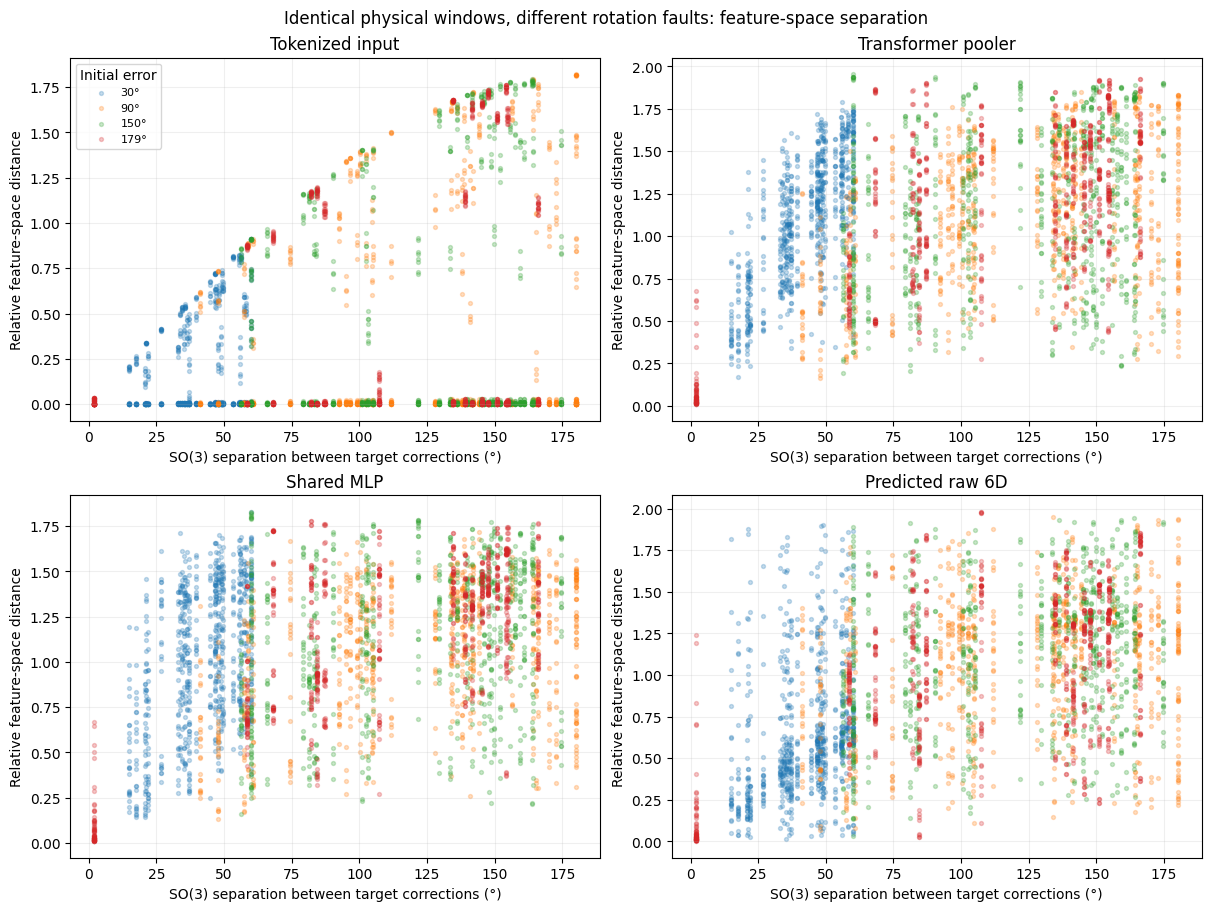

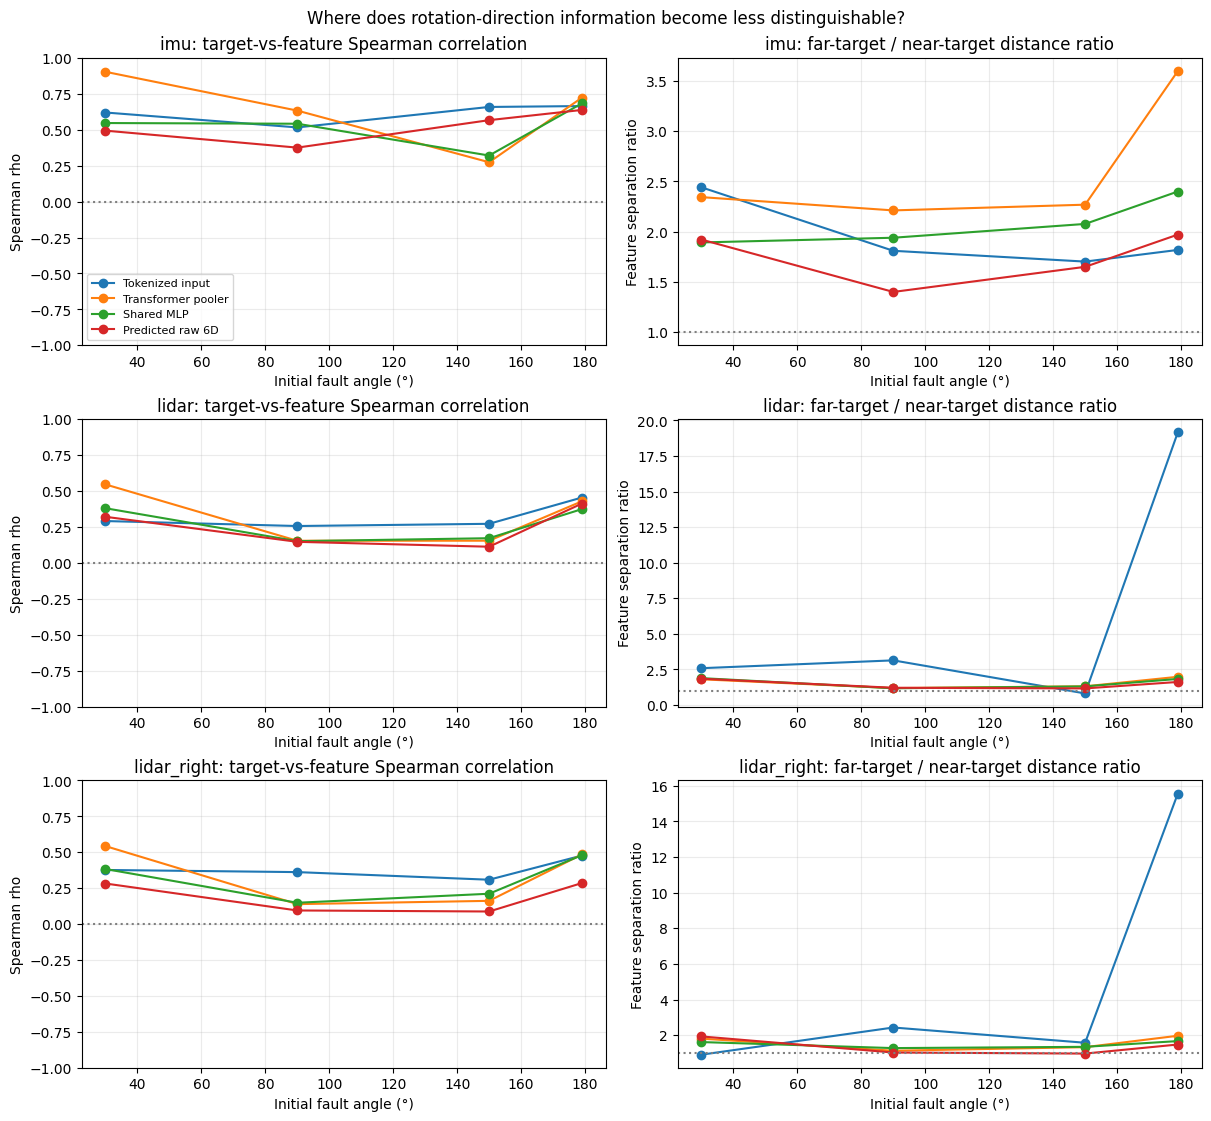

,key,angle_deg,layer,rank_correlation,far_near_distance_ratio,median_normalized_distance,n_pairs
0,imu,30.0,Tokenized input,0.621,2.441,0.501,264
1,imu,30.0,Transformer pooler,0.904,2.343,1.268,264
2,imu,30.0,Shared MLP,0.547,1.893,0.899,264
3,imu,30.0,Predicted raw 6D,0.494,1.921,0.580,264
4,imu,90.0,Tokenized input,0.517,1.810,1.198,264
5,imu,90.0,Transformer pooler,0.634,2.211,1.338,264
6,imu,90.0,Shared MLP,0.542,1.939,1.168,264
7,imu,90.0,Predicted raw 6D,0.376,1.401,1.186,264
8,imu,150.0,Tokenized input,0.659,1.702,1.327,264
9,imu,150.0,Transformer pooler,0.274,2.268,1.336,264


In [20]:
# Appendix 14D: Matched-rotation feature separability at four levels.
# For a fixed physical window, vary ONLY the injected calibration rotation.
# Ground truth is compared using the full SO(3) distance, never principal-axis cosine.
DIAG61_FEATURE_ANGLES = (30.0, 90.0, 150.0, 179.0)
DIAG61_FEATURE_BASE_DIRECTIONS = 6         # Six isotropic axes AND their six opposites.
DIAG61_FEATURE_KEYS = tuple(DIAG61_KEYS)   # Use ('lidar',) to speed up the experiment.
DIAG61_FEATURE_SEED = DIAG61_SEED + 7021

rng61 = np.random.default_rng(DIAG61_FEATURE_SEED)
base61 = rng61.normal(size=(DIAG61_FEATURE_BASE_DIRECTIONS, 3))
base61 = base61 / np.linalg.norm(base61, axis=1, keepdims=True)
directions61 = np.concatenate((base61, -base61), axis=0)

diag61_feature_records = []
diag61_pool_capture = {}

def diag61_pool_hook(_module, _inputs, output):
    diag61_pool_capture['pooled'] = output.detach()

handle61 = diag61_net.pooler.register_forward_hook(diag61_pool_hook)
diag61_net.eval()
try:
    with torch.inference_mode():
        for key in DIAG61_FEATURE_KEYS:
            key_id = CALIBRATION_KEYS.index(key)
            for angle in DIAG61_FEATURE_ANGLES:
                for dir_id, direction_np in enumerate(directions61):
                    direction = torch.tensor(direction_np, device=DEVICE, dtype=DTYPE)
                    xi = {sensor: torch.zeros(diag61_n, 6, device=DEVICE, dtype=DTYPE) for sensor in CALIBRATION_KEYS}
                    xi[key][:, :3] = float(np.deg2rad(angle)) * direction[None, :]
                    prior = apply_independent_prior_faults(diag61_physical.current_calibration, xi)
                    window = clone_with_current_calibration(diag61_physical, prior)
                    canonical = geometry_processor(window.streams, window.metadata, window.current_calibration)
                    tokens = tokenizer(canonical, calibration_keys=CALIBRATION_KEYS)
                    output = diag61_net(tokens)
                    pooled = diag61_pool_capture['pooled']
                    assert pooled.ndim == 3 and pooled.shape[:2] == (diag61_n, len(CALIBRATION_KEYS))
                    assert output.shared_features.shape[:2] == (diag61_n, len(CALIBRATION_KEYS))
                    input_x = (tokens.x * tokens.token_mask[..., None].to(dtype=tokens.x.dtype)).reshape(diag61_n, -1)
                    raw_output = output.predictions[key].rotation_6d
                    prior_R = prior[key].transform[:, :3, :3]
                    truth_R = window.targets[key].next_transform[:, :3, :3]
                    required_R = truth_R @ prior_R.transpose(-1, -2)
                    assert bool(torch.allclose(rotation_geodesic_deg(prior_R, truth_R), prior_R.new_full((diag61_n,), angle), atol=0.08, rtol=0))
                    for b, physical_index in enumerate(diag61_indices):
                        diag61_feature_records.append(dict(
                            key=key, angle_deg=angle, physical_index=int(physical_index), direction_id=dir_id,
                            target_R=required_R[b].cpu().numpy().copy(),
                            input=input_x[b].cpu().numpy().copy(),
                            pooled=pooled[b, key_id].cpu().numpy().copy(),
                            shared=output.shared_features[b, key_id].cpu().numpy().copy(),
                            raw6d=raw_output[b].cpu().numpy().copy(),
                        ))
                print(f'Feature cases complete: {key} / {angle:g}° / {len(directions61)} directions', flush=True)
finally:
    handle61.remove()
    diag61_pool_capture.clear()


def diag61_matrix_distance_deg(R1, R2):
    R = R1 @ R2.T
    v = np.array([R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]])
    return float(np.rad2deg(np.arctan2(0.5 * np.linalg.norm(v), 0.5 * (np.trace(R) - 1.0))))


def diag61_normalized_distance(a, b):
    """Dimensionless relative L2 distance. Interpret rank correlation within each layer, not raw cross-layer magnitudes."""
    scale = np.sqrt(0.5 * (np.dot(a, a) + np.dot(b, b)))
    return float(np.linalg.norm(a - b) / max(float(scale), 1e-10))

layers61 = {'Tokenized input': 'input', 'Transformer pooler': 'pooled', 'Shared MLP': 'shared', 'Predicted raw 6D': 'raw6d'}
rows61 = []
for (key, angle, physical_index), items in pd.DataFrame(diag61_feature_records).groupby(['key', 'angle_deg', 'physical_index'], sort=False):
    samples = items.to_dict('records')
    for a, b in combinations(samples, 2):
        target_deg = diag61_matrix_distance_deg(a['target_R'], b['target_R'])
        for layer, field in layers61.items():
            rows61.append(dict(key=key, angle_deg=angle, physical_index=physical_index, direction_a=a['direction_id'], direction_b=b['direction_id'],
                               layer=layer, gt_target_distance_deg=target_deg, normalized_feature_distance=diag61_normalized_distance(a[field], b[field])))

diag61_feature_df = pd.DataFrame(rows61)
diag61_feature_df.to_csv(DIAG61_DIR / 'matched_feature_pair_distances.csv', index=False)
summary61 = []
for (key, angle, layer), frame in diag61_feature_df.groupby(['key', 'angle_deg', 'layer'], sort=False):
    target = frame.gt_target_distance_deg
    dist = frame.normalized_feature_distance
    near, far = np.quantile(target, [0.25, 0.75])
    near_distance = float(dist[target <= near].median())
    far_distance = float(dist[target >= far].median())
    summary61.append(dict(key=key, angle_deg=angle, layer=layer,
                          rank_correlation=float(target.corr(dist, method='spearman')),
                          far_near_distance_ratio=far_distance / max(near_distance, 1e-10),
                          median_normalized_distance=float(dist.median()), n_pairs=len(frame)))
diag61_feature_summary = pd.DataFrame(summary61)
diag61_feature_summary.to_csv(DIAG61_DIR / 'feature_separability_summary.csv', index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for ax, layer in zip(axes.ravel(), layers61):
    sub = diag61_feature_df[diag61_feature_df.layer == layer]
    for angle, group in sub.groupby('angle_deg'):
        ax.scatter(group.gt_target_distance_deg, group.normalized_feature_distance, s=8, alpha=0.25, label=f'{angle:g}°')
    ax.set(xlabel='SO(3) separation between target corrections (°)', ylabel='Relative feature-space distance', title=layer)
    ax.grid(alpha=0.2)
axes[0, 0].legend(title='Initial error', fontsize=8)
fig.suptitle('Identical physical windows, different rotation faults: feature-space separation')
fig.savefig(DIAG61_DIR / 'feature_pair_scatter.png', dpi=170)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

fig, axes = plt.subplots(len(DIAG61_FEATURE_KEYS), 2, figsize=(12, 3.7 * len(DIAG61_FEATURE_KEYS)), squeeze=False, constrained_layout=True)
for i, key in enumerate(DIAG61_FEATURE_KEYS):
    for layer, group in diag61_feature_summary[diag61_feature_summary.key == key].groupby('layer', sort=False):
        group = group.sort_values('angle_deg')
        axes[i, 0].plot(group.angle_deg, group.rank_correlation, '-o', label=layer)
        axes[i, 1].plot(group.angle_deg, group.far_near_distance_ratio, '-o', label=layer)
    axes[i, 0].set(title=f'{key}: target-vs-feature Spearman correlation', ylabel='Spearman rho', xlabel='Initial fault angle (°)', ylim=(-1, 1))
    axes[i, 1].set(title=f'{key}: far-target / near-target distance ratio', ylabel='Feature separation ratio', xlabel='Initial fault angle (°)')
    for ax in axes[i]:
        ax.grid(alpha=0.25)
        ax.axhline(0 if ax is axes[i, 0] else 1, linestyle=':', color='gray')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Where does rotation-direction information become less distinguishable?')
fig.savefig(DIAG61_DIR / 'feature_separability_by_angle.png', dpi=170)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
display(diag61_feature_summary.round(3))


full        | imu         |    30° | 4 matched directions
full        | imu         |    90° | 4 matched directions
full        | imu         |   150° | 4 matched directions
full        | imu         |   179° | 4 matched directions
full        | lidar       |    30° | 4 matched directions
full        | lidar       |    90° | 4 matched directions
full        | lidar       |   150° | 4 matched directions
full        | lidar       |   179° | 4 matched directions
full        | lidar_right |    30° | 4 matched directions
full        | lidar_right |    90° | 4 matched directions
full        | lidar_right |   150° | 4 matched directions
full        | lidar_right |   179° | 4 matched directions
active_only | imu         |    30° | 4 matched directions
active_only | imu         |    90° | 4 matched directions
active_only | imu         |   150° | 4 matched directions
active_only | imu         |   179° | 4 matched directions
active_only | lidar       |    30° | 4 matched directions
active_only | 

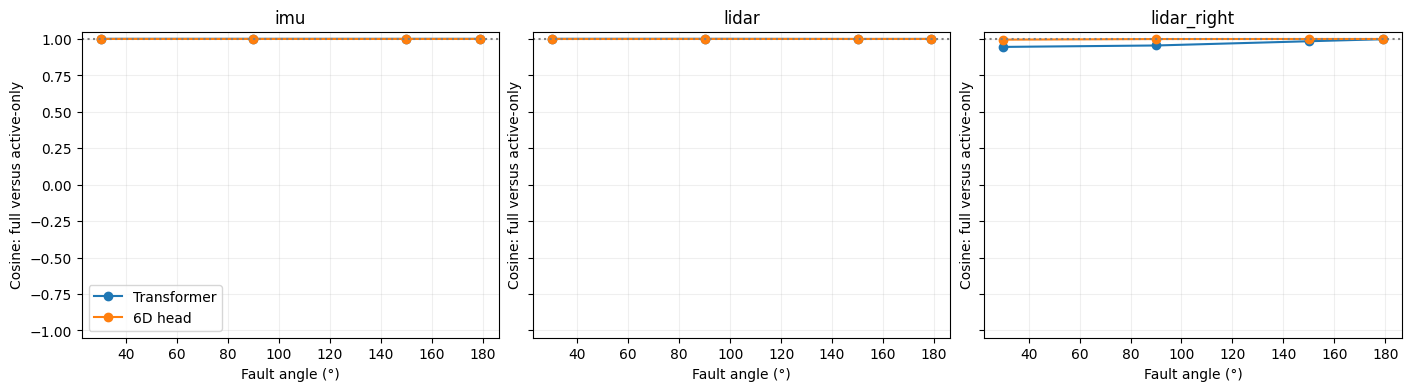

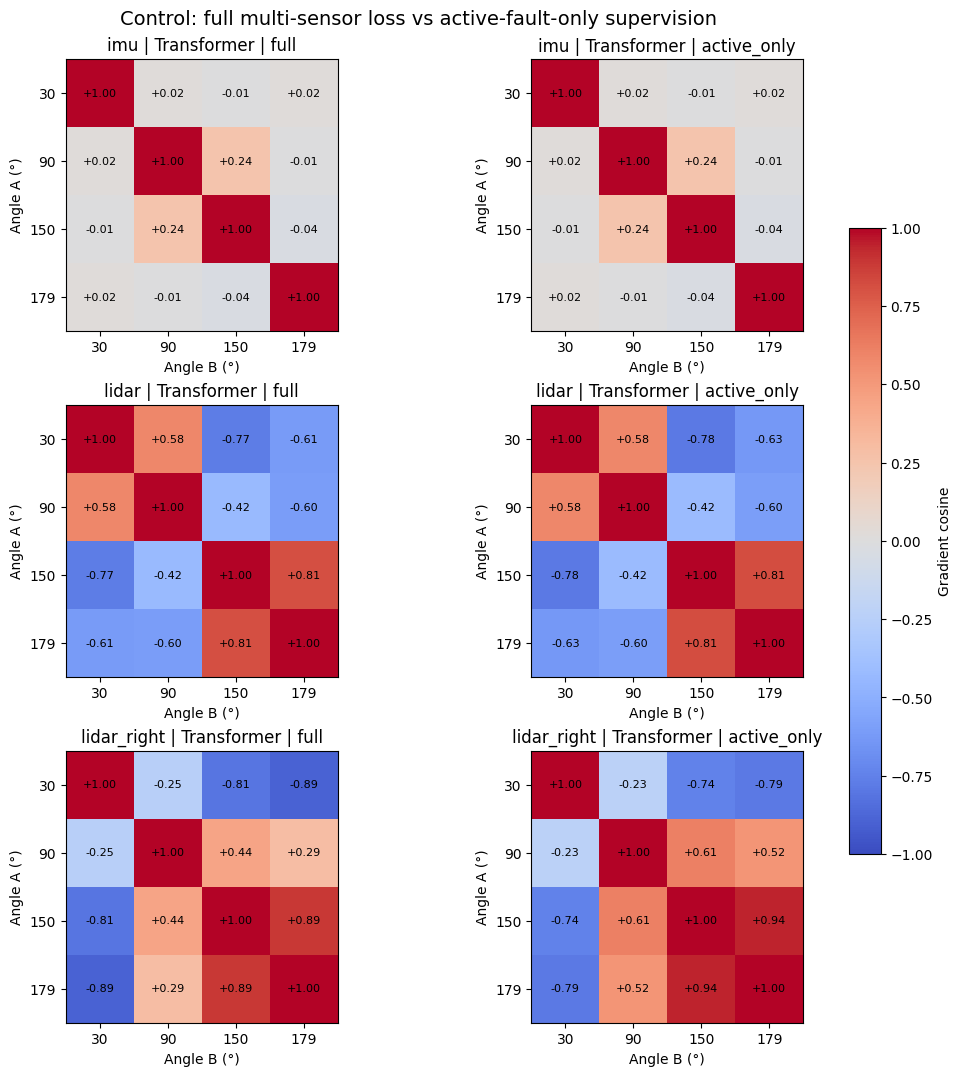

,key,group,angle_a,angle_b,full_cos,active_only_cos,active_minus_full
19,imu,6D head,30.0,150.0,0.048,0.048,0.000
20,imu,6D head,30.0,179.0,0.041,0.041,0.000
7,imu,Pooler,30.0,150.0,0.056,0.056,0.000
8,imu,Pooler,30.0,179.0,0.131,0.131,0.000
13,imu,Shared MLP,30.0,150.0,0.169,0.169,0.000
14,imu,Shared MLP,30.0,179.0,0.060,0.060,0.000
1,imu,Transformer,30.0,150.0,-0.005,-0.006,-0.000
2,imu,Transformer,30.0,179.0,0.017,0.017,0.000
121,lidar,6D head,30.0,150.0,-0.277,-0.276,0.001
122,lidar,6D head,30.0,179.0,-0.271,-0.271,-0.000


Positive active_minus_full = LESS conflict after removing healthy-sensor targets.


In [21]:
# Notebook 61, Appendix 15A. Compare FULL versus ACTIVE-ONLY gradients on identical fault cases.
# Requires Appendix 14A setup (diag61_net, diag61_cases, DIAG61_*), plus notebook imports/helpers.
# All gradients are evaluated at the same frozen 2.30 weights. No optimizer steps.
import re
from itertools import combinations

CONTROL61_OBJECTIVES = ('full', 'active_only')
CONTROL61_DIR = DIAG61_DIR / 'full_vs_active_only'
CONTROL61_DIR.mkdir(parents=True, exist_ok=True)

control61_net = diag61_net
control61_net.eval()
control61_named = [(name, param) for name, param in control61_net.named_parameters() if param.requires_grad]
control61_params = [param for name, param in control61_named]
control61_groups = {
    'Transformer': [i for i, (name, _) in enumerate(control61_named) if name.startswith('transformer_encoder.')],
    'Pooler': [i for i, (name, _) in enumerate(control61_named) if name.startswith('pooler.')],
    'Shared MLP': [i for i, (name, _) in enumerate(control61_named) if name.startswith('mlp_body.')],
    '6D head': [i for i, (name, _) in enumerate(control61_named) if name.startswith('head_6d.')],
}
assert all(control61_groups.values()), f'Could not find one or more expected model blocks: {control61_groups}'
assert sorted(i for indices in control61_groups.values() for i in indices) == list(range(len(control61_params)))

# Find real Transformer layer parameter names. This supports common nested encoder layouts.
control61_layer_by_index = {}
for i, (name, _) in enumerate(control61_named):
    if not name.startswith('transformer_encoder.'):
        continue
    match = re.search(r'(?:^|\.)(?:layers|blocks)\.(\d+)\.', name)
    if match:
        layer_id = int(match.group(1))
        control61_layer_by_index.setdefault(layer_id, []).append(i)
assert len(control61_layer_by_index) == NUM_TRANSFORMER_LAYERS, (
    f'Expected {NUM_TRANSFORMER_LAYERS} Transformer layers, found {sorted(control61_layer_by_index)}. '
    f'Example names: {[name for name, _ in control61_named if name.startswith("transformer_encoder.")][:12]}'
)
for layer_id, indices in sorted(control61_layer_by_index.items()):
    control61_groups[f'Layer {layer_id:02d}'] = indices
control61_remainder = sorted(set(control61_groups['Transformer']) - set(i for indices in control61_layer_by_index.values() for i in indices))
if control61_remainder:
    control61_groups['Transformer input/other'] = control61_remainder


def control61_objective(candidate, case, objective):
    """Exact Notebook 61 loss or only faulted sensor's supervised rotation target."""
    window, key = case['window'], case['key']
    output = model_predictions(window, model_override=candidate)
    if objective == 'full':
        loss, _ = compute_6d_objective(window, output)
    elif objective == 'active_only':
        prior = window.current_calibration[key].transform[:, :3, :3]
        truth = window.targets[key].next_transform[:, :3, :3]
        desired = matrix_to_rotation_6d(truth @ prior.transpose(-1, -2))
        predicted = output.predictions[key].rotation_6d
        loss = LOSS_WEIGHTS.rotation_weight * LOSS_WEIGHTS.rotation_6d_weight * (predicted - desired).square().mean()
    else:
        raise ValueError(objective)
    return loss


def control61_cosine(a, b):
    na, nb = a.norm(), b.norm()
    return float((a @ b) / (na * nb).clamp_min(1e-12))


# Cache only MEAN gradients per objective, fault sensor, angle and model block/layer.
# Do not keep per-sample autograd graphs or parameter updates.
control61_grads = {}
control61_rows = []
for objective in CONTROL61_OBJECTIVES:
    for key in DIAG61_KEYS:
        for angle in DIAG61_ANGLES:
            cases = [case for case in diag61_cases[angle] if case['key'] == key]
            sums = {group: None for group in control61_groups}
            for case in cases:
                loss = control61_objective(control61_net, case, objective)
                grads = torch.autograd.grad(loss, control61_params, allow_unused=True)
                for group, indices in control61_groups.items():
                    vector = torch.cat([
                        (grads[i].detach() if grads[i] is not None else torch.zeros_like(control61_params[i])).reshape(-1)
                        for i in indices
                    ]).cpu()
                    sums[group] = vector if sums[group] is None else sums[group] + vector
                del grads, loss
            for group in control61_groups:
                value = sums[group] / len(cases)
                assert bool(torch.isfinite(value).all()), (objective, key, angle, group)
                control61_grads[(objective, key, angle, group)] = value
                control61_rows.append(dict(objective=objective, key=key, angle_deg=angle, group=group, n_cases=len(cases), mean_gradient_norm=float(value.norm())))
            print(f'{objective:11s} | {key:11s} | {angle:5g}° | {len(cases)} matched directions', flush=True)

control61_grad_df = pd.DataFrame(control61_rows)
control61_grad_df.to_csv(CONTROL61_DIR / 'mean_gradient_norms.csv', index=False)
control61_pair_rows = []
for key in DIAG61_KEYS:
    for group in control61_groups:
        for a, b in combinations(DIAG61_ANGLES, 2):
            full_cos = control61_cosine(control61_grads[('full', key, a, group)], control61_grads[('full', key, b, group)])
            active_cos = control61_cosine(control61_grads[('active_only', key, a, group)], control61_grads[('active_only', key, b, group)])
            control61_pair_rows.append(dict(key=key, group=group, angle_a=a, angle_b=b, full_cos=full_cos, active_only_cos=active_cos, active_minus_full=active_cos - full_cos))
control61_pair_df = pd.DataFrame(control61_pair_rows)
control61_pair_df.to_csv(CONTROL61_DIR / 'full_vs_active_only_cosines.csv', index=False)


# Compare full and active-only gradients at the SAME angle to quantify healthy-sensor influence.
control61_same_angle_rows = []
for key in DIAG61_KEYS:
    for angle in DIAG61_ANGLES:
        for group in ('Transformer', 'Pooler', 'Shared MLP', '6D head'):
            gf = control61_grads[('full', key, angle, group)]
            ga = control61_grads[('active_only', key, angle, group)]
            control61_same_angle_rows.append(dict(key=key, angle_deg=angle, group=group,
                                                  full_vs_active_cos=control61_cosine(gf, ga),
                                                  full_norm=float(gf.norm()), active_norm=float(ga.norm())))
control61_same_angle_df = pd.DataFrame(control61_same_angle_rows)
control61_same_angle_df.to_csv(CONTROL61_DIR / 'full_vs_active_at_same_angle.csv', index=False)
fig, axes = plt.subplots(1, len(DIAG61_KEYS), figsize=(14, 3.8), sharey=True, constrained_layout=True)
for ax, key in zip(np.atleast_1d(axes), DIAG61_KEYS):
    for group in ('Transformer', '6D head'):
        data = control61_same_angle_df[(control61_same_angle_df.key == key) & (control61_same_angle_df.group == group)].sort_values('angle_deg')
        ax.plot(data.angle_deg, data.full_vs_active_cos, '-o', label=group)
    ax.axhline(1.0, color='gray', linestyle=':')
    ax.set(title=key, xlabel='Fault angle (°)', ylabel='Cosine: full versus active-only', ylim=(-1.05, 1.05))
    ax.grid(alpha=.2)
axes[0].legend()
fig.savefig(CONTROL61_DIR / 'full_vs_active_same_angle_alignment.png', dpi=170)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

# Heatmaps: do the healthy-sensor gradients account for the LiDAR fine/coarse conflict?
fig, axes = plt.subplots(len(DIAG61_KEYS), 2, figsize=(10.8, 3.55 * len(DIAG61_KEYS)), constrained_layout=True, squeeze=False)
for row, key in enumerate(DIAG61_KEYS):
    for col, objective in enumerate(CONTROL61_OBJECTIVES):
        vectors = [control61_grads[(objective, key, a, 'Transformer')] for a in DIAG61_ANGLES]
        mat = np.array([[control61_cosine(x, y) for y in vectors] for x in vectors])
        ax = axes[row, col]
        image61 = ax.imshow(mat, cmap='coolwarm', vmin=-1, vmax=1)
        ax.set_xticks(range(len(DIAG61_ANGLES)), [f'{a:g}' for a in DIAG61_ANGLES])
        ax.set_yticks(range(len(DIAG61_ANGLES)), [f'{a:g}' for a in DIAG61_ANGLES])
        ax.set(xlabel='Angle B (°)', ylabel='Angle A (°)', title=f'{key} | Transformer | {objective}')
        for i in range(len(DIAG61_ANGLES)):
            for j in range(len(DIAG61_ANGLES)):
                ax.text(j, i, f'{mat[i,j]:+.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image61, ax=axes, shrink=.65, label='Gradient cosine')
fig.suptitle('Control: full multi-sensor loss vs active-fault-only supervision', fontsize=14)
fig.savefig(CONTROL61_DIR / 'full_vs_active_only_transformer_heatmaps.png', dpi=175)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

important_pairs = [(30., 150.), (30., 179.)]
summary61 = control61_pair_df[control61_pair_df.apply(lambda r: (r.angle_a, r.angle_b) in important_pairs and r.group in ('Transformer', 'Pooler', 'Shared MLP', '6D head'), axis=1)]
display(summary61.sort_values(['key', 'group', 'angle_a', 'angle_b']).round(3))
print('Positive active_minus_full = LESS conflict after removing healthy-sensor targets.')


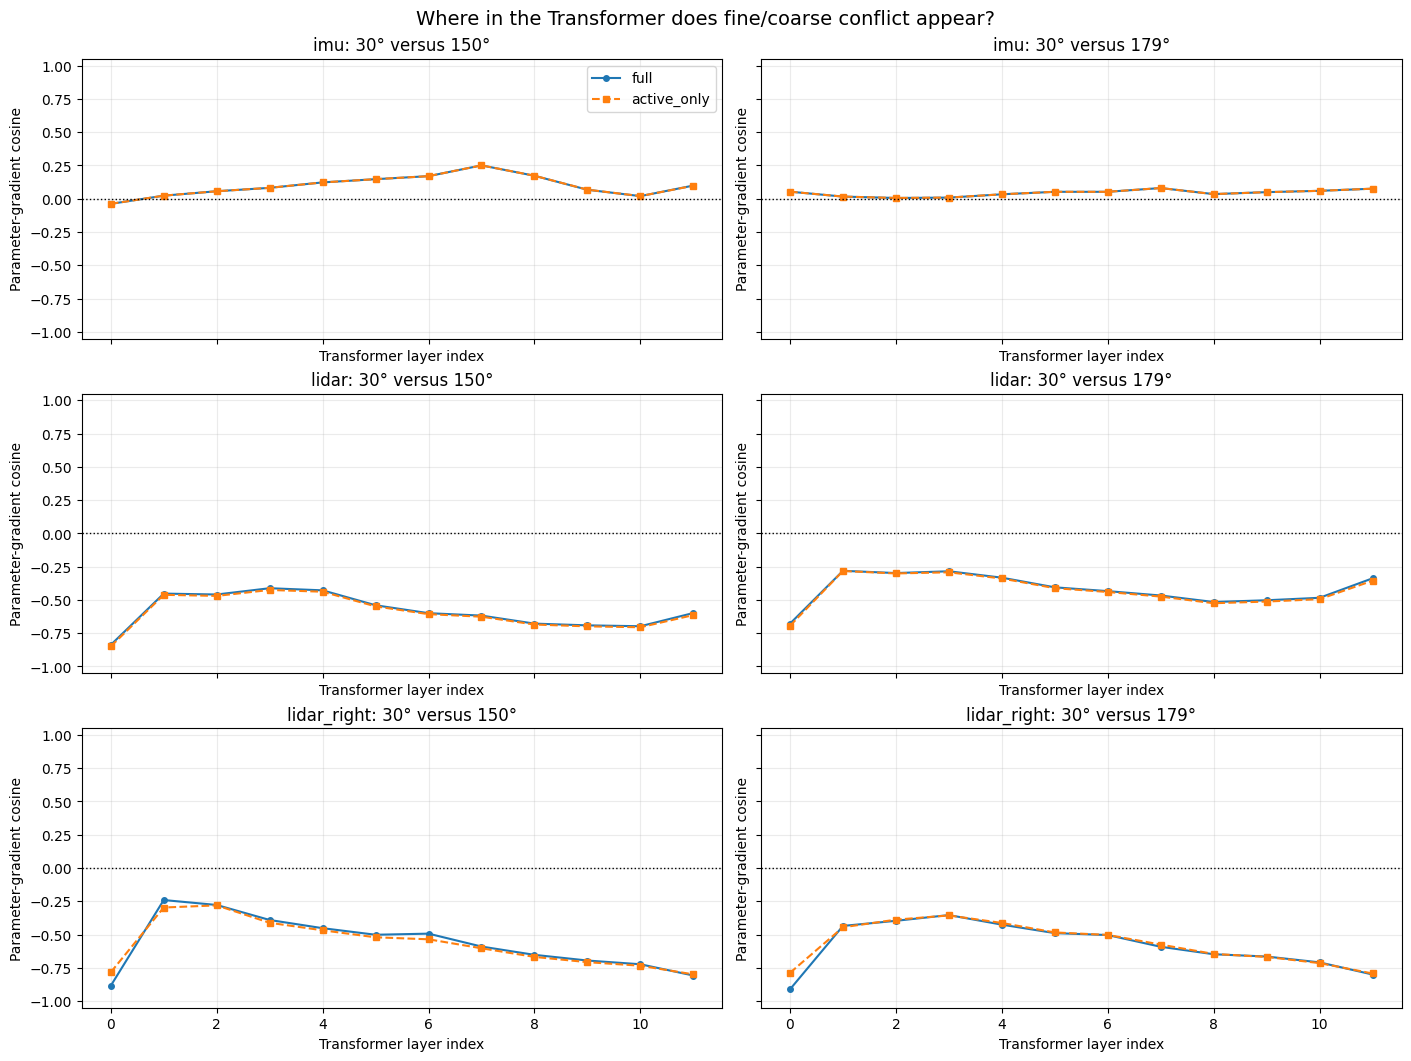

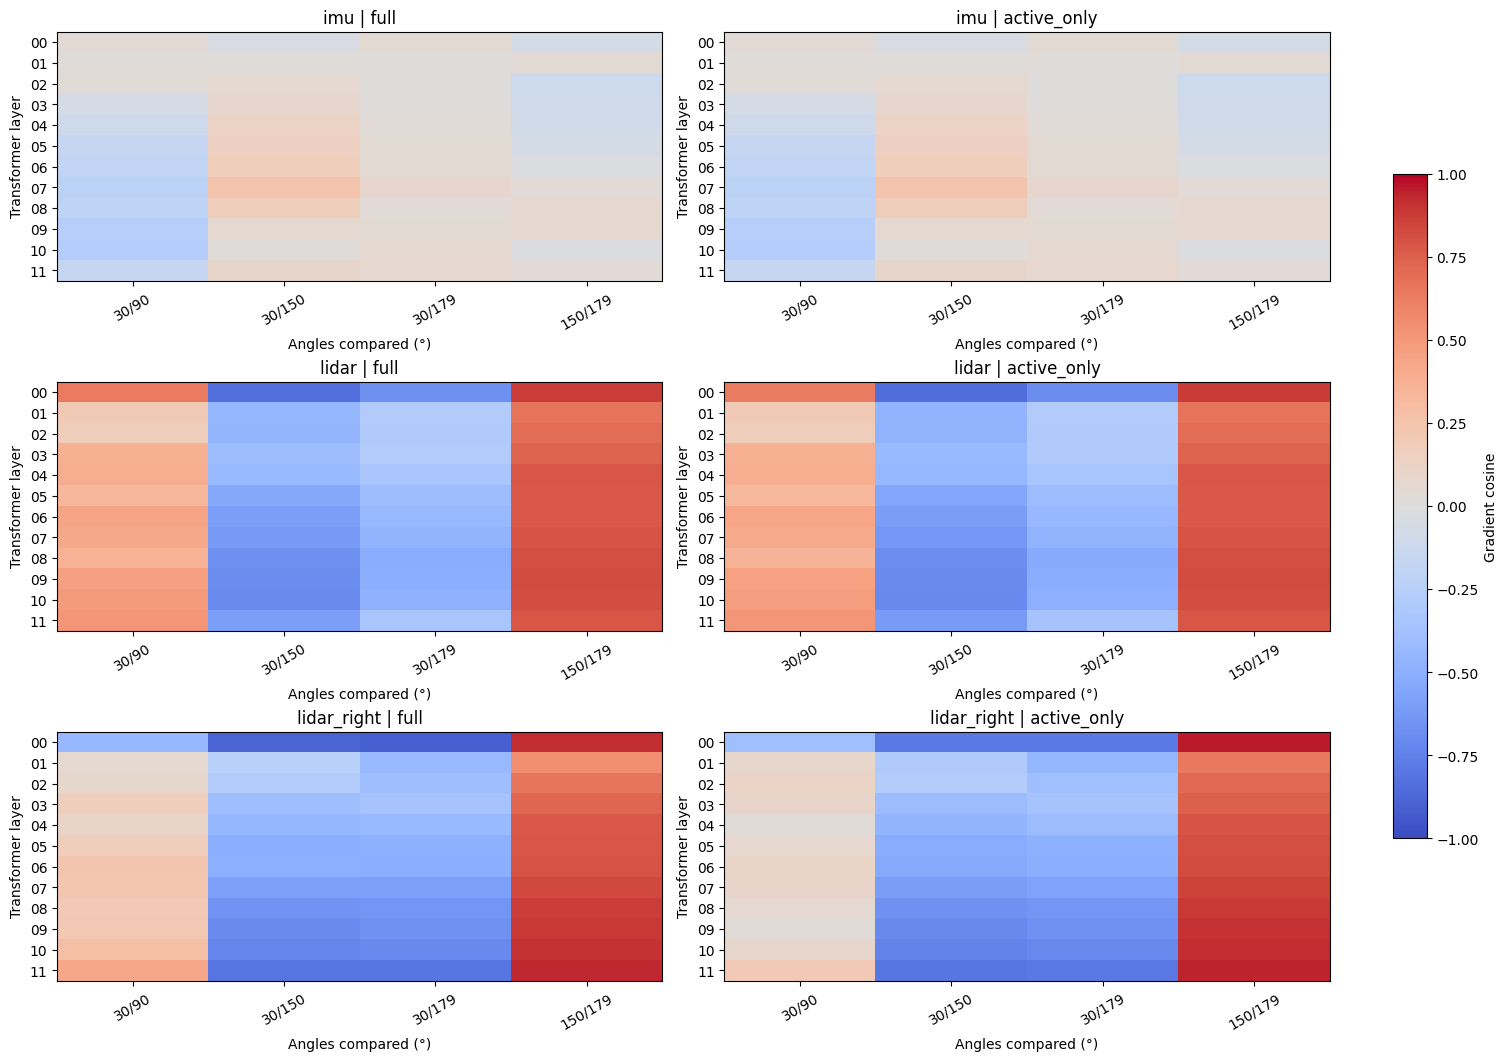

Negative cosine in early layers suggests shared feature extraction interference. Negative only late suggests specialization might help.


objective          active_only   full
key         layer                    
imu         0            0.053  0.053
            1            0.016  0.016
            2            0.006  0.006
            3            0.009  0.009
            4            0.034  0.034
            5            0.052  0.052
            6            0.052  0.052
            7            0.080  0.080
            8            0.035  0.035
            9            0.050  0.050
            10           0.060  0.060
            11           0.076  0.076
lidar       0           -0.694 -0.678
            1           -0.283 -0.281
            2           -0.301 -0.298
            3           -0.293 -0.285
            4           -0.339 -0.333
            5           -0.412 -0.405
            6           -0.440 -0.434
            7           -0.475 -0.467
            8           -0.525 -0.516
            9           -0.512 -0.503
            10          -0.494 -0.484
            11          -0.356 -0.338
lidar_right 0           -0.788 -0.912
            1           -0.446 -0.435
            2           -0.388 -0.397
            3           -0.357 -0.354
            4           -0.413 -0.426
            5           -0.484 -0.489
            6           -0.503 -0.504
            7           -0.576 -0.592
            8           -0.646 -0.648
            9           -0.668 -0.665
            10          -0.715 -0.709
            11          -0.793 -0.800

In [22]:
# Notebook 61, Appendix 15B. Per-layer fine/coarse gradient conflicts, for both objectives.
# Requires the previous Appendix 15A cell (it reuses gradients from EXACTLY the same cases).
assert 'control61_grads' in globals() and len(control61_layer_by_index) == NUM_TRANSFORMER_LAYERS
LAYER61_DIR = CONTROL61_DIR / 'layerwise'
LAYER61_DIR.mkdir(parents=True, exist_ok=True)
layer_ids = sorted(control61_layer_by_index)
layer_groups = [f'Layer {i:02d}' for i in layer_ids]
layer_pairs = [(30.0, 90.0), (30.0, 150.0), (30.0, 179.0), (150.0, 179.0)]

layer61_rows = []
for key in DIAG61_KEYS:
    for group in layer_groups:
        for a, b in layer_pairs:
            for objective in CONTROL61_OBJECTIVES:
                grad_a = control61_grads[(objective, key, a, group)]
                grad_b = control61_grads[(objective, key, b, group)]
                layer61_rows.append(dict(key=key, layer=int(group.split()[1]), angle_a=a, angle_b=b, objective=objective,
                                         cosine=control61_cosine(grad_a, grad_b), grad_a_norm=float(grad_a.norm()), grad_b_norm=float(grad_b.norm())))
layer61_df = pd.DataFrame(layer61_rows)
layer61_df.to_csv(LAYER61_DIR / 'layerwise_gradient_conflicts.csv', index=False)

# Individual layer profile, revealing whether early or late attention blocks carry conflict.
fig, axes = plt.subplots(len(DIAG61_KEYS), 2, figsize=(14, 3.5 * len(DIAG61_KEYS)), sharex=True, sharey=True, squeeze=False, constrained_layout=True)
for row, key in enumerate(DIAG61_KEYS):
    for col, pair in enumerate(((30., 150.), (30., 179.))):
        ax = axes[row, col]
        for objective, style in (('full', '-o'), ('active_only', '--s')):
            values = layer61_df[(layer61_df.key == key) & (layer61_df.objective == objective) & (layer61_df.angle_a == pair[0]) & (layer61_df.angle_b == pair[1])].sort_values('layer')
            ax.plot(values.layer, values.cosine, style, label=objective, markersize=4)
        ax.axhline(0, color='black', linestyle=':', linewidth=1)
        ax.set(xlabel='Transformer layer index', ylabel='Parameter-gradient cosine', title=f'{key}: {pair[0]:g}° versus {pair[1]:g}°', ylim=(-1.05, 1.05))
        ax.grid(alpha=.25)
axes[0, 0].legend()
fig.suptitle('Where in the Transformer does fine/coarse conflict appear?', fontsize=14)
fig.savefig(LAYER61_DIR / 'per_layer_conflict_curves.png', dpi=175)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

# Heatmap across layers and all requested angle pairs, independently for each sensor and objective.
fig, axes = plt.subplots(len(DIAG61_KEYS), 2, figsize=(15, 3.5 * len(DIAG61_KEYS)), squeeze=False, constrained_layout=True)
for row, key in enumerate(DIAG61_KEYS):
    for col, objective in enumerate(CONTROL61_OBJECTIVES):
        matrix = np.array([[control61_cosine(control61_grads[(objective, key, a, group)], control61_grads[(objective, key, b, group)]) for a, b in layer_pairs] for group in layer_groups])
        ax = axes[row, col]
        im = ax.imshow(matrix, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
        ax.set_yticks(range(len(layer_ids)), [f'{i:02d}' for i in layer_ids])
        ax.set_xticks(range(len(layer_pairs)), [f'{a:g}/{b:g}' for a, b in layer_pairs], rotation=30)
        ax.set(title=f'{key} | {objective}', xlabel='Angles compared (°)', ylabel='Transformer layer')
fig.colorbar(im, ax=axes, shrink=.7, label='Gradient cosine')
fig.savefig(LAYER61_DIR / 'per_layer_conflict_heatmaps.png', dpi=175)
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

print('Negative cosine in early layers suggests shared feature extraction interference. Negative only late suggests specialization might help.')
display(layer61_df[layer61_df.angle_a.eq(30.) & layer61_df.angle_b.eq(179.)].pivot_table(index=['key', 'layer'], columns='objective', values='cosine').round(3))


# New stochastic PCG

Start adamw: 500 updates, full arbitrary 3D range, fresh AdamW
adamw  step    0/500 | probe=0.7973 cart=0.375 3D=0.773 30°=0.602 179°=0.643 conflict_layers=nan
adamw  step   50/500 | probe=0.7751 cart=0.369 3D=0.752 30°=0.543 179°=0.641 conflict_layers=0.54
adamw  step  100/500 | probe=0.7578 cart=0.375 3D=0.736 30°=0.516 179°=0.657 conflict_layers=0.54
adamw  step  150/500 | probe=0.7473 cart=0.376 3D=0.722 30°=0.496 179°=0.664 conflict_layers=0.69
adamw  step  200/500 | probe=0.7409 cart=0.380 3D=0.721 30°=0.498 179°=0.663 conflict_layers=0.85
adamw  step  250/500 | probe=0.7463 cart=0.377 3D=0.722 30°=0.496 179°=0.670 conflict_layers=0.62
adamw  step  300/500 | probe=0.7454 cart=0.383 3D=0.724 30°=0.524 179°=0.665 conflict_layers=1.00
adamw  step  350/500 | probe=0.7267 cart=0.382 3D=0.707 30°=0.492 179°=0.669 conflict_layers=0.62
adamw  step  400/500 | probe=0.7296 cart=0.388 3D=0.710 30°=0.507 179°=0.671 conflict_layers=0.23
adamw  step  450/500 | probe=0.7147 cart=0.392 3D=0.692 

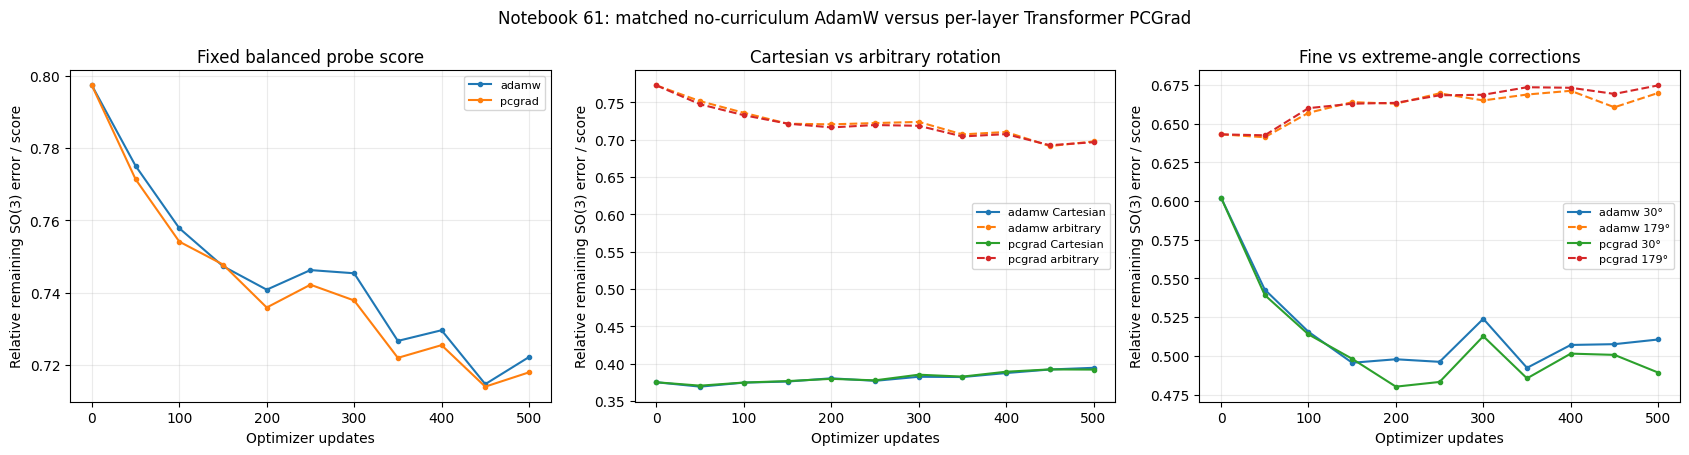

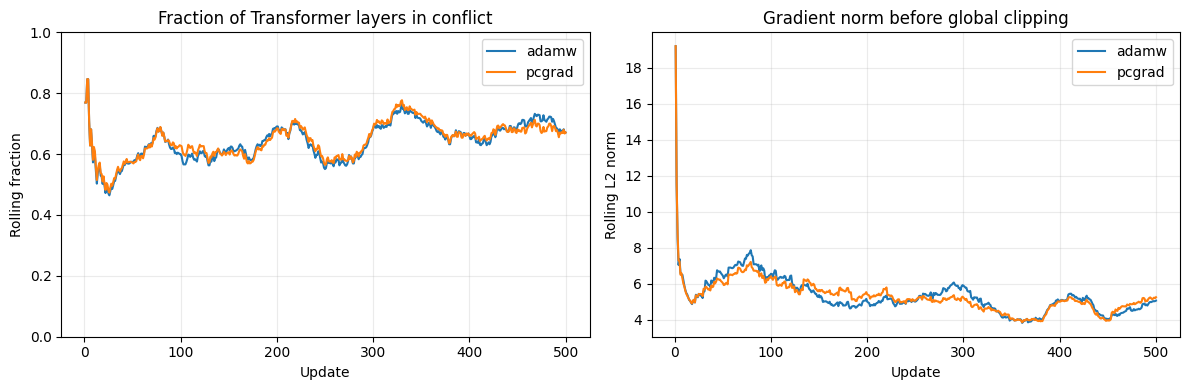

arm                         adamw  pcgrad
fault_key   axis_type axis               
imu         arbitrary U1    0.867   0.870
                      U2    0.967   0.952
            cartesian X     0.210   0.209
                      Y     0.139   0.140
                      Z     0.548   0.553
lidar       arbitrary U1    0.566   0.569
                      U2    0.623   0.626
            cartesian X     0.879   0.855
                      Y     0.191   0.190
                      Z     0.262   0.264
lidar_right arbitrary U1    0.563   0.566
                      U2    0.600   0.599
            cartesian X     0.882   0.876
                      Y     0.196   0.194
                      Z     0.244   0.247

,arm,score,cartesian_mean,arbitrary_mean,angle_30,angle_179
10,adamw,0.7222,0.3945,0.6977,0.5106,0.6698
21,pcgrad,0.7180,0.3922,0.6967,0.4892,0.6747


In [23]:
# Notebook 61, Appendix 15C. STAGE-FREE, matched AdamW vs per-layer Transformer PCGrad.
# Run after model, prior_samplers_61, build_probe_bank, probe_metrics, and cell 15A.
# This is a new reversible stochastic experiment, NOT a curriculum and NOT the full run.
# All checkpoints and artifacts go into a dedicated directory. The main model/optimizer are untouched.

PCG61_RUN = True
PCG61_STEPS = 500
PCG61_BATCH_PER_TASK = 16           # Fine 16 + coarse 16 per optimizer update (32 fault examples).
PCG61_REPORT_EVERY = 50
PCG61_CARTESIAN_PROBABILITY = 0.50   # Same distribution for fine/coarse, one faulted sensor.
PCG61_IDENTITY_PROBABILITY = 0.10
PCG61_HEAD_LR = 2e-5
PCG61_TRANSFORMER_LR = 2e-6
PCG61_SEED = TRAIN_AUG_SEED + 6_430_000
PCG61_INIT_CHECKPOINT = SOURCE_230_PATH
PCG61_PROBE_WINDOWS = 8
PCG61_PROBE_DIRECTIONS = 2
PCG61_PROBE_ANGLES = (0., 30., 60., 90., 120., 150., 175., 179.)
PCG61_GRADIENT_SCOPE = 'per_layer_transformer'  # Do NOT project the shared MLP / 6D head in this first ablation.
PCG61_SAVE_CANDIDATES = True
PCG61_DIR = RUN_DIR / 'plots' / 'pcgrad_stochastic_no_curriculum'
PCG61_DIR.mkdir(parents=True, exist_ok=True)

assert PCG61_INIT_CHECKPOINT.is_file()
assert 0 <= PCG61_CARTESIAN_PROBABILITY <= 1
assert 0 <= PCG61_IDENTITY_PROBABILITY < 1
assert PCG61_GRADIENT_SCOPE == 'per_layer_transformer'

# Two identical batches in each update: both arms use the same physical windows, sensor-fault
# samplers, 0-60° fine examples, 60-179° coarse examples, and 50/50 Cartesian/arbitrary axes.
# Unlike stage C, their fine/coarse proportions are EXACTLY balanced on every step.
@torch.no_grad()
def pcg61_fault_window(physical, *, group, generator):
    assert group in ('fine', 'coarse')
    truth = physical.current_calibration
    n = next(iter(truth.values())).transform.shape[0]
    cart_name = 'cart_fine' if group == 'fine' else 'cart_coarse'
    sphere_name = 'arb_fine' if group == 'fine' else 'arb_coarse_179'
    cart_xi = prior_samplers_61[cart_name](truth, generator=generator)[1]
    arb_xi = prior_samplers_61[sphere_name](truth, generator=generator)[1]
    cart_mask = torch.rand(n, device=DEVICE, generator=generator) < PCG61_CARTESIAN_PROBABILITY
    identity_mask = torch.rand(n, device=DEVICE, generator=generator) < PCG61_IDENTITY_PROBABILITY
    xi = {key: torch.where(cart_mask[:, None], cart_xi[key], arb_xi[key]).masked_fill(identity_mask[:, None], 0.) for key in CALIBRATION_KEYS}
    return clone_with_current_calibration(physical, apply_independent_prior_faults(truth, xi))


def pcg61_sample_paired_step(step, index_rng):
    # A fresh generator per step ensures BOTH arms see exactly the same physical data and faults.
    indices = index_rng.choice(len(train_dataset), size=min(PCG61_BATCH_PER_TASK, len(train_dataset)), replace=False)
    base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
    generator = augmentation_generator(PCG61_SEED + 10_003 * step)
    with torch.no_grad():
        physical = physical_augmenter(base, generator=generator).augmented_window
        fine_window = pcg61_fault_window(physical, group='fine', generator=generator)
        coarse_window = pcg61_fault_window(physical, group='coarse', generator=generator)
    return fine_window, coarse_window


def pcg61_parameter_partition(candidate):
    params = [(name, parameter) for name, parameter in candidate.named_parameters() if parameter.requires_grad]
    layers = {}
    for idx, (name, _) in enumerate(params):
        if name.startswith('transformer_encoder.'):
            match = re.search(r'(?:^|\.)(?:layers|blocks)\.(\d+)\.', name)
            if match:
                layers.setdefault(f'layer_{int(match.group(1)):02d}', []).append(idx)
            else:
                layers.setdefault('embedding_and_other', []).append(idx)
    count = len([name for name in layers if name.startswith('layer_')])
    assert count == NUM_TRANSFORMER_LAYERS, (count, list(layers))
    used = [idx for group in layers.values() for idx in group]
    assert len(set(used)) == len(used)
    return [param for _, param in params], layers


def pcg61_apply_gradients(params, grad_fine, grad_coarse, groups, *, projected):
    """Symmetric two-task PCGrad, independently within each Transformer layer.

    Projection uses ORIGINAL fine/coarse gradients (order-independent for two tasks).
    Non-Transformer parameters always get the ordinary 0.5*(fine + coarse) gradient.
    """
    merged = [(a + b) * 0.5 for a, b in zip(grad_fine, grad_coarse)]
    cosines = []
    conflict_count = 0
    for indices in groups.values():
        dot = sum((grad_fine[i] * grad_coarse[i]).sum() for i in indices)
        norm_f = sum((grad_fine[i] * grad_fine[i]).sum() for i in indices)
        norm_c = sum((grad_coarse[i] * grad_coarse[i]).sum() for i in indices)
        cosines.append(float(dot / torch.sqrt((norm_f * norm_c).clamp_min(1e-24))))
        if projected and float(dot.detach()) < 0 and float(norm_f.detach()) > 1e-20 and float(norm_c.detach()) > 1e-20:
            conflict_count += 1
            # Symmetric PCGrad; both projections are calculated from the unmodified gradients.
            alpha_f = dot / norm_c
            alpha_c = dot / norm_f
            for i in indices:
                merged[i] = 0.5 * (grad_fine[i] - alpha_f * grad_coarse[i] + grad_coarse[i] - alpha_c * grad_fine[i])
    for p, grad in zip(params, merged):
        p.grad = grad.detach()
    return len([x for x in cosines if x < 0]) / max(len(cosines), 1), float(np.mean(cosines)), conflict_count


if PCG61_RUN:
    pcg61_probe_bank = build_probe_bank(val_dataset, n_windows=PCG61_PROBE_WINDOWS, batch_size=PCG61_PROBE_WINDOWS, seed=PROBE_SEED + 6401,
                                         angles=PCG61_PROBE_ANGLES, n_sphere_directions=PCG61_PROBE_DIRECTIONS)
    pcg61_initial = copy.deepcopy(diag61_net).to(device=DEVICE, dtype=DTYPE)
    load_training_checkpoint(PCG61_INIT_CHECKPOINT, model=pcg61_initial, map_location=DEVICE, restore_rng_state=False)
    pcg61_initial.eval()
    pcg61_history = []
    pcg61_pair_history = []
    pcg61_step_history = []
    pcg61_initial_cpu_rng = torch.get_rng_state().clone()
    pcg61_initial_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    pcg61_initial_np_rng = np.random.get_state()
    pcg61_initial_py_rng = random.getstate()
    try:
        for arm in ('adamw', 'pcgrad'):
            candidate = copy.deepcopy(pcg61_initial)
            candidate.requires_grad_(True)
            params, transformer_groups = pcg61_parameter_partition(candidate)
            opt = torch.optim.AdamW(parameter_groups(candidate, transformer_lr=PCG61_TRANSFORMER_LR, other_lr=PCG61_HEAD_LR), weight_decay=WEIGHT_DECAY)
            index_rng = np.random.default_rng(PCG61_SEED + 91)  # Reset: exact same sampled index sequence for both arms.
            best_score = float('inf')
            print(f'Start {arm}: {PCG61_STEPS} updates, full arbitrary 3D range, fresh AdamW', flush=True)
            for step in range(PCG61_STEPS + 1):
                train_fine = train_coarse = float('nan')
                grad_norm = conflict_fraction = mean_cosine = float('nan')
                if step > 0:
                    candidate.train()
                    opt.zero_grad(set_to_none=True)
                    fine_window, coarse_window = pcg61_sample_paired_step(step, index_rng)
                    fine_loss, _ = compute_6d_objective(fine_window, model_predictions(fine_window, model_override=candidate))
                    fine_grad = torch.autograd.grad(fine_loss, params, allow_unused=True)
                    coarse_loss, _ = compute_6d_objective(coarse_window, model_predictions(coarse_window, model_override=candidate))
                    coarse_grad = torch.autograd.grad(coarse_loss, params, allow_unused=True)
                    fine_grad = [torch.zeros_like(p) if grad is None else grad.detach() for p, grad in zip(params, fine_grad)]
                    coarse_grad = [torch.zeros_like(p) if grad is None else grad.detach() for p, grad in zip(params, coarse_grad)]
                    conflict_fraction, mean_cosine, n_projected = pcg61_apply_gradients(params, fine_grad, coarse_grad, transformer_groups, projected=(arm == 'pcgrad'))
                    grad_norm = float(torch.nn.utils.clip_grad_norm_(params, GRADIENT_CLIP_NORM))
                    if not np.isfinite(grad_norm):
                        raise FloatingPointError(f'Nonfinite {arm} gradient at step {step}')
                    opt.step()
                    train_fine, train_coarse = float(fine_loss.detach()), float(coarse_loss.detach())
                    pcg61_step_history.append(dict(arm=arm, step=step, train_fine=train_fine, train_coarse=train_coarse,
                                                   grad_norm_before_clip=grad_norm, fraction_conflicting_transformer_layers=conflict_fraction,
                                                   mean_transformer_layer_cosine=mean_cosine))
                    del fine_window, coarse_window, fine_loss, coarse_loss, fine_grad, coarse_grad
                if step == 0 or step % PCG61_REPORT_EVERY == 0 or step == PCG61_STEPS:
                    frame = evaluate_probe_bank(candidate, pcg61_probe_bank, name=arm)
                    metrics, pairs = probe_metrics(frame)
                    # Monitor 30, 90, 150 and 179 independently, to see the fine/coarse tradeoff.
                    angle_scores = {f'angle_{int(a)}': float(frame.loc[frame.angle_deg.eq(a) & frame.axis_type.ne('identity'), 'relative_remaining'].mean()) for a in (30., 90., 150., 179.)}
                    row = dict(arm=arm, step=step, train_fine=train_fine, train_coarse=train_coarse,
                               grad_norm_before_clip=grad_norm, conflicting_layer_fraction=conflict_fraction, mean_layer_cosine=mean_cosine, **metrics, **angle_scores)
                    pcg61_history.append(row)
                    pairs = pairs.copy()
                    pairs['arm'], pairs['step'] = arm, step
                    pcg61_pair_history.extend(pairs.to_dict('records'))
                    print(f'{arm:6s} step {step:4d}/{PCG61_STEPS} | probe={metrics["score"]:.4f} cart={metrics["cartesian_mean"]:.3f} '
                          f'3D={metrics["arbitrary_mean"]:.3f} 30°={angle_scores["angle_30"]:.3f} '
                          f'179°={angle_scores["angle_179"]:.3f} conflict_layers={conflict_fraction:.2f}', flush=True)
                    if metrics['score'] < best_score:
                        best_score = metrics['score']
                        if PCG61_SAVE_CANDIDATES:
                            torch.save({'model_state_dict': {k: v.detach().cpu().clone() for k, v in candidate.state_dict().items()},
                                        'optimizer_state_dict': opt.state_dict(), 'step': step, 'score': best_score,
                                        'arm': arm, 'source_checkpoint': str(PCG61_INIT_CHECKPOINT)}, PCG61_DIR / f'{arm}_best.pt')
            if PCG61_SAVE_CANDIDATES:
                torch.save({'model_state_dict': {k: v.detach().cpu().clone() for k, v in candidate.state_dict().items()},
                            'optimizer_state_dict': opt.state_dict(), 'step': PCG61_STEPS, 'arm': arm}, PCG61_DIR / f'{arm}_last.pt')
            del candidate, opt
    finally:
        torch.set_rng_state(pcg61_initial_cpu_rng)
        if pcg61_initial_cuda_rng is not None:
            torch.cuda.set_rng_state_all(pcg61_initial_cuda_rng)
        np.random.set_state(pcg61_initial_np_rng)
        random.setstate(pcg61_initial_py_rng)
        del pcg61_initial
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
        print('PCGrad comparison complete. Original Notebook 61 model, optimizer, and RNG states unchanged.')

    pcg61_df = pd.DataFrame(pcg61_history)
    pcg61_pair_df = pd.DataFrame(pcg61_pair_history)
    pcg61_step_df = pd.DataFrame(pcg61_step_history)
    pcg61_df.to_csv(PCG61_DIR / 'pcgrad_vs_adamw_learning_curves.csv', index=False)
    pcg61_pair_df.to_csv(PCG61_DIR / 'pcgrad_vs_adamw_sensor_axes.csv', index=False)
    pcg61_step_df.to_csv(PCG61_DIR / 'pcgrad_stepwise_gradient_conflicts.csv', index=False)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for arm, part in pcg61_df.groupby('arm', sort=False):
        axes[0].plot(part.step, part.score, '-o', label=arm, markersize=3)
        axes[1].plot(part.step, part.cartesian_mean, '-o', label=f'{arm} Cartesian', markersize=3)
        axes[1].plot(part.step, part.arbitrary_mean, '--o', label=f'{arm} arbitrary', markersize=3)
        axes[2].plot(part.step, part.angle_30, '-o', label=f'{arm} 30°', markersize=3)
        axes[2].plot(part.step, part.angle_179, '--o', label=f'{arm} 179°', markersize=3)
    for ax, title in zip(axes, ('Fixed balanced probe score', 'Cartesian vs arbitrary rotation', 'Fine vs extreme-angle corrections')):
        ax.set(xlabel='Optimizer updates', ylabel='Relative remaining SO(3) error / score', title=title)
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.suptitle('Notebook 61: matched no-curriculum AdamW versus per-layer Transformer PCGrad')
    fig.tight_layout()
    fig.savefig(PCG61_DIR / 'pcgrad_vs_adamw.png', dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for arm, sub in pcg61_step_df.groupby('arm', sort=False):
        rolling = sub.sort_values('step')
        window_size = min(50, max(1, len(rolling) // 5))
        axes[0].plot(rolling.step, rolling.fraction_conflicting_transformer_layers.rolling(window_size, min_periods=1).mean(), label=arm)
        axes[1].plot(rolling.step, rolling.grad_norm_before_clip.rolling(window_size, min_periods=1).mean(), label=arm)
    axes[0].set(title='Fraction of Transformer layers in conflict', xlabel='Update', ylabel='Rolling fraction', ylim=(0, 1))
    axes[1].set(title='Gradient norm before global clipping', xlabel='Update', ylabel='Rolling L2 norm')
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend()
    fig.tight_layout()
    fig.savefig(PCG61_DIR / 'pcgrad_gradient_conflict_diagnostics.png', dpi=175)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    # Per-sensor and direction performance, including the problematic left/right LiDAR X/Z cases.
    final61 = pcg61_pair_df.sort_values('step').groupby(['arm', 'fault_key', 'axis_type', 'axis'], as_index=False).tail(1)
    display(final61.pivot_table(index=['fault_key', 'axis_type', 'axis'], columns='arm', values='relative_remaining').round(3))
    display(pcg61_df.groupby('arm', sort=False).tail(1)[['arm', 'score', 'cartesian_mean', 'arbitrary_mean', 'angle_30', 'angle_179']].round(4))
else:
    print('Set PCG61_RUN=True to execute the matched stochastic comparison.')


# Training

In [ ]:

if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

In [ ]:
if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, FULL_TARGET_EPOCHS):
        stage = curriculum_stage_for_epoch(epoch)
        # Begin each new stage with a fresh scheduler counter, not fresh optimizer moments.
        stage_transition = epoch > 0 and curriculum_stage_for_epoch(epoch - 1)['name'] != stage['name']
        if stage_transition:
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_PROBES)
            print(f'CURRICULUM TRANSITION to {stage["name"]}, preserving all AdamW moments and current LR')
        train_shuffle_generator.manual_seed(RANDOM_SEED + 12001 + epoch)
        train = run_6d_epoch(train_loader, training=True, generator=train_generator, stage=stage, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        validation = run_6d_epoch(val_loader, training=False, generator=augmentation_generator(VAL_AUG_SEED + 6100), stage=stage, max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        global_step += train['optimizer_updates']
        improved = False
        row = dict(epoch=epoch + 1, global_step=global_step, stage=stage['name'], stage_cartesian_probability=stage['cartesian_probability'], stage_arbitrary_max_deg=stage['arbitrary_max_deg'],
                   train_loss=train['loss_total'], val_loss=validation['loss_total'], train_rotation_6d=train['loss_rotation_6d'], val_rotation_6d=validation['loss_rotation_6d'],
                   train_active_deg=train['active_rotation_error_deg'], val_active_deg=validation['active_rotation_error_deg'])
        if (epoch + 1) % PROBE_EVERY_EPOCHS == 0:
            probe = evaluate_probe_bank(model, full_probe_bank, name='curriculum_probe')
            global_metrics, pairs = probe_metrics(probe)
            stage_metrics, _ = probe_metrics(probe, arbitrary_max_deg=stage['arbitrary_max_deg'])
            row.update({f'probe_{k}': v for k, v in global_metrics.items()})
            row['stage_probe_score'] = stage_metrics['score']
            scheduler.step(stage_metrics['score'])
            pairs['epoch'], pairs['global_step'], pairs['stage'] = epoch + 1, global_step, stage['name']
            pair_history.extend(pairs.to_dict('records'))
            if global_metrics['score'] < best_score:
                best_score, best_epoch = global_metrics['score'], epoch + 1
                improved = True
        row.update(head_mlp_lr=optimizer.param_groups[1]['lr'], transformer_lr=optimizer.param_groups[0]['lr'])
        history.append(row)
        if improved:
            save_61_checkpoint(BEST_CHECKPOINT_PATH, epoch + 1, row)
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        if pair_history:
            pd.DataFrame(pair_history).to_csv(PAIR_HISTORY_PATH, index=False)
        save_61_checkpoint(LAST_CHECKPOINT_PATH, epoch + 1, row)
        score_text = f'full={row["probe_score"]:.4f} stage={row["stage_probe_score"]:.4f} cart={row["probe_cartesian_mean"]:.3f} 3d={row["probe_arbitrary_mean"]:.3f}' if 'probe_score' in row else 'no probe'
        print(f'Epoch {epoch+1:3d}/{FULL_TARGET_EPOCHS} [{stage["name"]}] train={train["loss_total"]:.4f} val={validation["loss_total"]:.4f} | {score_text} | LR={row["transformer_lr"]:.1e}/{row["head_mlp_lr"]:.1e}' + (' BEST' if improved else ''), flush=True)
    print('Completed full curriculum. Best epoch:', best_epoch, '| fixed full-range score:', best_score)
else:
    print('Full training not requested; old 002.31 checkpoints are untouched.')


In [ ]:
if HISTORY_PATH.is_file():
    history_view = pd.read_csv(HISTORY_PATH)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    axes[0].plot(history_view.epoch, history_view.train_loss, label='Train')
    axes[0].plot(history_view.epoch, history_view.val_loss, label='Validation')
    axes[0].set(title='Supervised objective', xlabel='Epoch', ylabel='6D loss')
    if 'probe_score' in history_view:
        axes[1].plot(history_view.epoch, history_view.probe_score, label='Fixed full-range checkpoint score')
        axes[1].plot(history_view.epoch, history_view.stage_probe_score, '--', label='Stage scheduler score')
        axes[1].plot(history_view.epoch, history_view.probe_cartesian_mean, ':', label='Cartesian')
        axes[1].plot(history_view.epoch, history_view.probe_arbitrary_mean, ':', label='3D')
    axes[1].set(title='Checkpoint vs stage-limited scores', xlabel='Epoch', ylabel='Remaining SO(3) ratio / score')
    axes[2].plot(history_view.epoch, history_view.transformer_lr, label='Transformer')
    axes[2].plot(history_view.epoch, history_view.head_mlp_lr, label='Pooler / MLP / head')
    axes[2].set(title='Restorable AdamW learning rates', xlabel='Epoch', ylabel='LR')
    for ax in axes:
        for boundary in FULL_STAGE_END_EPOCHS:
            ax.axvline(boundary + 0.5, linestyle=':', color='gray')
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RUN_DIR / '61_curriculum_training_overview.png', dpi=175)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    print('Saved full-run history:', HISTORY_PATH)
else:
    print('No curriculum full-run history yet.')


## 11. Post-training paired one-step comparison: `002.30` versus curriculum best

The checkpoint comparison remains unchanged in scope: fixed paired Cartesian X/Y/Z plus independently sampled arbitrary axes for all three sensors, both signs, including 179°. Results report real SO(3) residuals and raw axis cosines (interpreted carefully near π), and are **not** the same validation bank used for checkpoint selection. Use `EVAL_RUN=True` only after a curriculum `best.pt` exists.


In [ ]:
EVAL_DIR = RUN_DIR / 'plots' / 'post_training_mixed_axes_comparison'
if EVAL_RUN:
    EVAL_DIR.mkdir(parents=True, exist_ok=True)
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'Full-run best checkpoint missing: {BEST_CHECKPOINT_PATH}')
    if EVAL_INCLUDE_227 and not SOURCE_227_PATH.is_file():
        raise FileNotFoundError(f'Optional 002.27 checkpoint missing: {SOURCE_227_PATH}')

    def load_frozen_6d(path):
        candidate = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
        load_training_checkpoint(path, model=candidate, map_location=DEVICE, restore_rng_state=False)
        return candidate.eval().requires_grad_(False)

    eval_models = {'2.30 source': load_frozen_6d(SOURCE_230_PATH), '61 best': load_frozen_6d(BEST_CHECKPOINT_PATH)}
    if EVAL_INCLUDE_227:
        eval_models['2.27 original'] = load_frozen_6d(SOURCE_227_PATH)
    eval_cases = build_probe_bank(val_dataset, n_windows=EVAL_WINDOWS, batch_size=EVAL_BATCH_SIZE, seed=VAL_AUG_SEED + 6_110_101,
                                  angles=EVAL_ANGLES_DEG, n_sphere_directions=EVAL_3D_DIRECTIONS)
    print('Complete checkpoints:', SOURCE_230_PATH, BEST_CHECKPOINT_PATH)
    print('Evaluation case count:', len(eval_cases), '| each checkpoint gets exactly the same cases')
    print('Model parameter delta L2:', math.sqrt(sum(float((a - b).square().sum()) for a, b in zip(eval_models['2.30 source'].parameters(), eval_models['61 best'].parameters()))))
else:
    print('Set EVAL_RUN=True after training to load 002.30 and 61 best for paired validation.')


In [ ]:
if EVAL_RUN:
    one_frames = []
    for label, candidate in eval_models.items():
        print('Paired one-step evaluation:', label, flush=True)
        one_frames.append(evaluate_probe_bank(candidate, eval_cases, name=label))
    one_df = pd.concat(one_frames, ignore_index=True)
    one_df['axis_group'] = np.where(one_df.axis_type == 'cartesian', one_df.axis, np.where(one_df.axis_type == 'arbitrary', '3D', 'I'))
    one_df.to_csv(EVAL_DIR / 'one_step_individual.csv', index=False)
    one_summary = one_df.groupby(['model', 'fault_key', 'axis_type', 'axis_group', 'axis', 'angle_deg', 'signed_angle_deg'], as_index=False).agg(
        mean_after_deg=('after_deg', 'mean'), median_after_deg=('after_deg', 'median'), p90_after_deg=('after_deg', lambda x: x.quantile(.90)),
        mean_correction_deg=('correction_deg', 'mean'), mean_axis_cosine=('axis_cosine', 'mean'),
        success_10deg=('after_deg', lambda x: (x < 10).mean()), success_30deg=('after_deg', lambda x: (x < 30).mean()), n=('after_deg', 'size'))
    one_summary.to_csv(EVAL_DIR / 'one_step_summary_signed.csv', index=False)
    pair_keys = ['fault_key', 'axis_type', 'axis', 'signed_angle_deg', 'physical_index']
    paired = one_df[one_df.model.isin(('2.30 source', '61 best'))].pivot(index=pair_keys, columns='model', values='after_deg').dropna()
    assert len(paired) * 2 == len(one_df[one_df.model.isin(('2.30 source', '61 best'))]), 'One-step cases are not properly paired.'
    paired['improvement_deg'] = paired['2.30 source'] - paired['61 best']
    paired.reset_index().to_csv(EVAL_DIR / 'one_step_paired_improvement.csv', index=False)
    active = one_df[one_df.angle_deg > 0]
    print('Mean residual ratio by sensor/axis family (lower is better):')
    display(active.groupby(['model', 'fault_key', 'axis_group']).relative_remaining.mean().unstack('axis_group').round(3))
    print('Mean SO(3) residual at ±179° by sensor/axis family (degrees):')
    display(active[active.angle_deg == 179.].groupby(['model', 'fault_key', 'axis_group']).after_deg.mean().unstack('axis_group').round(2))
    print('Paired improvement in degrees across angles: positive means 61 best is better.')
    display(paired.groupby(level=['fault_key', 'axis_type', 'axis']).improvement_deg.mean().unstack('axis').round(2))
else:
    print('One-step comparison disabled.')


In [ ]:
if EVAL_RUN:
    color = {'2.30 source': 'tab:blue', '61 best': 'tab:orange', '2.27 original': 'tab:green'}

    def plot_four_column(metric, title, y_label, filename, *, reference=False, ylim=None):
        fig, axes = plt.subplots(3, 4, figsize=(19, 11), sharex=True, sharey=True)
        for row, key in enumerate(CALIBRATION_KEYS):
            for col, direction in enumerate(('X', 'Y', 'Z', '3D')):
                ax = axes[row, col]
                subset = one_df[(one_df.fault_key == key) & (one_df.axis_group == direction) & (one_df.angle_deg > 0)]
                curves = subset.groupby(['model', 'sign', 'angle_deg'], as_index=False).agg(value=(metric, 'mean'))
                for model_name in eval_models:
                    for sign, style in ((1, '-'), (-1, '--')):
                        line = curves[(curves.model == model_name) & (curves.sign == sign)].sort_values('angle_deg')
                        ax.plot(line.angle_deg, line.value, style, marker='.', color=color[model_name], label=f'{model_name} {"+" if sign == 1 else "−"}')
                if reference:
                    ax.plot(EVAL_ANGLES_DEG, EVAL_ANGLES_DEG, ':', color='gray', linewidth=1.2, label='No correction / GT magnitude')
                if ylim is not None:
                    ax.set_ylim(*ylim)
                ax.set_title(f'{key} / {direction}')
                ax.grid(alpha=.25)
                if row == 2:
                    ax.set_xlabel('Initial error magnitude (°)')
                if col == 0:
                    ax.set_ylabel(y_label)
        axes[0, 0].legend(fontsize=7, ncol=2)
        fig.suptitle(title, fontsize=15)
        fig.tight_layout()
        fig.savefig(EVAL_DIR / filename, dpi=175)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)

    plot_four_column('after_deg', 'One-window SO(3) correction: Cartesian X/Y/Z and arbitrary 3D', 'Mean remaining error (°)', 'one_step_residuals.png', reference=True, ylim=(0, 180))
    plot_four_column('correction_deg', 'Predicted correction magnitude vs target magnitude', 'Mean predicted step (°)', 'one_step_correction_magnitude.png', reference=True, ylim=(0, 180))
    plot_four_column('axis_cosine', 'Predicted-vs-GT principal axis cosine (caution near 180°)', 'Mean signed axis cosine', 'one_step_axis_cosine.png', ylim=(-1.05, 1.05))

    # Inspect 179° distributions rather than only signed means; opposite axes may be close on SO(3).
    fig, axes = plt.subplots(3, 4, figsize=(18, 10), sharex=True, sharey=True)
    for row, key in enumerate(CALIBRATION_KEYS):
        for col, direction in enumerate(('X', 'Y', 'Z', '3D')):
            ax = axes[row, col]
            values = one_df[(one_df.fault_key == key) & (one_df.axis_group == direction) & (one_df.angle_deg == 179.0)]
            for label in eval_models:
                arr = values.loc[values.model == label, 'axis_cosine'].dropna().to_numpy()
                ax.hist(arr, bins=np.linspace(-1, 1, 17), histtype='step', linewidth=1.6, color=color[label], label=f'{label} (n={len(arr)})')
            ax.axvline(0, linestyle=':', color='gray')
            ax.set_title(f'{key} / {direction}')
            ax.grid(alpha=.2)
            if row == 2:
                ax.set_xlabel('Axis cosine at 179°')
            if col == 0:
                ax.set_ylabel('Number of cases')
    axes[0, 0].legend(fontsize=7)
    fig.suptitle('Per-case 179° correction-direction distributions')
    fig.tight_layout()
    fig.savefig(EVAL_DIR / 'one_step_179_axis_cosine_histograms.png', dpi=175)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))
    values = one_df[one_df.angle_deg == 179.0]
    heatmaps = {label: values[values.model == label].groupby(['fault_key', 'axis_group']).after_deg.mean().unstack('axis_group').reindex(index=CALIBRATION_KEYS, columns=('X', 'Y', 'Z', '3D')) for label in ('2.30 source', '61 best')}
    heatmaps['Improvement'] = heatmaps['2.30 source'] - heatmaps['61 best']
    for ax, (label, matrix) in zip(axes, heatmaps.items()):
        val = matrix.to_numpy()
        limit = max(15, float(np.nanmax(np.abs(val))))
        pic = ax.imshow(val, cmap='RdBu' if label == 'Improvement' else 'viridis_r', vmin=-limit if label == 'Improvement' else 0, vmax=limit if label == 'Improvement' else 180)
        ax.set_xticks(range(4), ('X', 'Y', 'Z', '3D'))
        ax.set_yticks(range(3), CALIBRATION_KEYS)
        ax.set_title(label)
        for i in range(3):
            for j in range(4):
                ax.text(j, i, f'{matrix.iloc[i, j]:+.1f}' if label == 'Improvement' else f'{matrix.iloc[i, j]:.1f}', ha='center', va='center', fontsize=9)
        fig.colorbar(pic, ax=ax, shrink=.76)
    fig.suptitle('One-step remaining error at ±179° and paired improvement (degrees)')
    fig.tight_layout()
    fig.savefig(EVAL_DIR / 'one_step_179_heatmaps.png', dpi=175)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
else:
    print('One-step plotting disabled.')


## 12. Matched chronological 12-window rollouts

Both frozen models receive the same initial prior and real physical motion windows, then independently feed their own prediction back into the next input. Only the faulted sensor's **rotation** is updated; healthy rotations, translation and time offsets stay fixed. Compare full SO(3) residuals, signed axis cosines, and near-π failure tails.


In [ ]:
@torch.inference_mode()
def evaluate_12_window_rollouts(models, *, sequences=EVAL_ROLLOUT_SEQUENCES, starts=EVAL_ROLLOUT_STARTS,
                                truths=EVAL_ROLLOUT_TRUTHS, steps=EVAL_ROLLOUT_STEPS, angles=EVAL_ROLLOUT_ANGLES,
                                sphere_directions=EVAL_ROLLOUT_3D_DIRECTIONS, seed=VAL_AUG_SEED + 6_110_303):
    """Independent model feedback, matched GT and per-window raw measurements; only faulted R updates."""
    direction_specs = [('cartesian', axis, tuple(np.eye(3)[j])) for j, axis in enumerate('XYZ')]
    direction_specs += [('arbitrary', f'U{j+1}', tuple(vec)) for j, vec in enumerate(fixed_sphere_directions(sphere_directions, seed + 123))]
    direction_specs += [('identity', 'I', (0., 0., 0.))]
    I = torch.eye(3, device=DEVICE, dtype=DTYPE)
    records = []
    for seq_id, sequence in enumerate(sequences):
        sequence_indices = np.asarray(val_dataset.window_indices_for_sequence(sequence), dtype=np.int64)
        last_start = len(sequence_indices) - steps
        if last_start < 0:
            raise ValueError(f'{sequence}: expected {steps} consecutive windows, found {len(sequence_indices)}')
        start_positions = np.unique(np.linspace(0, last_start, min(starts, last_start + 1)).round().astype(int))
        for start_id, start in enumerate(start_positions):
            window_indices = sequence_indices[start:start + steps]
            for truth_id in range(truths):
                truth_seed = seed + seq_id * 1_000_003 + start_id * 100_003 + truth_id * 1009
                physical_windows = []
                for index in window_indices:
                    base = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=DTYPE)
                    # Reset to the same seed for each window so GT is constant across time.
                    physical = physical_augmenter(base, generator=augmentation_generator(truth_seed)).augmented_window
                    physical_windows.append(physical)
                truth = physical_windows[0].current_calibration
                for physical in physical_windows[1:]:
                    for key in CALIBRATION_KEYS:
                        torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                        torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)
                for fault_key in CALIBRATION_KEYS:
                    for family, axis, direction in direction_specs:
                        direction_vec = torch.tensor(direction, device=DEVICE, dtype=DTYPE)
                        these_angles = (0.,) if family == 'identity' else tuple(a for a in angles if a > 0)
                        for initial_angle in these_angles:
                            for sign in ((0,) if initial_angle == 0 else (1, -1)):
                                xi = {key: torch.zeros(1, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                                xi[fault_key][:, :3] = float(np.deg2rad(initial_angle)) * sign * direction_vec[None, :]
                                initial_states = apply_independent_prior_faults(truth, xi)
                                for model_label, candidate in models.items():
                                    states = {key: replace(state, transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in initial_states.items()}
                                    for step in range(steps + 1):
                                        prior_R = states[fault_key].transform[:, :3, :3]
                                        truth_R = truth[fault_key].transform[:, :3, :3]
                                        residual = float(rotation_geodesic_deg(prior_R, truth_R)[0])
                                        record = dict(model=model_label, sequence=sequence, start_index=int(window_indices[0]), truth_id=truth_id,
                                                      fault_key=fault_key, axis_type=family, axis=axis, axis_group=axis if family == 'cartesian' else ('3D' if family == 'arbitrary' else 'I'),
                                                      sign=int(sign), initial_angle_deg=float(initial_angle), signed_angle_deg=float(sign * initial_angle),
                                                      step=step, residual_deg=residual, predicted_step_deg=np.nan, axis_cosine=np.nan)
                                        if step < steps:
                                            input_window = clone_with_current_calibration(physical_windows[step], states)
                                            predicted_R = model_predictions(input_window, model_override=candidate).predictions[fault_key].delta_rotation
                                            desired_R = truth_R @ prior_R.transpose(-1, -2)
                                            record['predicted_step_deg'] = float(rotation_geodesic_deg(predicted_R, I.expand_as(predicted_R))[0])
                                            record['axis_cosine'] = float(rotation_axis_cosine(predicted_R, desired_R)[0])
                                            next_T = states[fault_key].transform.clone()
                                            next_T[:, :3, :3] = predicted_R @ prior_R
                                            states = dict(states)
                                            states[fault_key] = replace(states[fault_key], transform=next_T)
                                        records.append(record)
                print(f'Finished matched 12-window rollouts: {sequence}, start={int(window_indices[0])}, truth {truth_id + 1}/{truths}', flush=True)
    return pd.DataFrame.from_records(records)


In [ ]:
if EVAL_RUN:
    eval_rollouts = evaluate_12_window_rollouts(eval_models)
    eval_rollouts.to_csv(EVAL_DIR / 'rollout_12_window_individual.csv', index=False)
    rollout_summary = eval_rollouts.groupby(['model', 'fault_key', 'axis_type', 'axis_group', 'axis', 'initial_angle_deg', 'sign', 'step'], as_index=False).agg(
        mean_residual_deg=('residual_deg', 'mean'), median_residual_deg=('residual_deg', 'median'), p90_residual_deg=('residual_deg', lambda x: x.quantile(.9)),
        mean_axis_cosine=('axis_cosine', 'mean'), success_10deg=('residual_deg', lambda x: (x < 10).mean()),
        success_30deg=('residual_deg', lambda x: (x < 30).mean()), n=('residual_deg', 'size'))
    rollout_summary.to_csv(EVAL_DIR / 'rollout_12_window_summary_signed.csv', index=False)
    final = eval_rollouts[(eval_rollouts.step == EVAL_ROLLOUT_STEPS) & (eval_rollouts.initial_angle_deg == 179.)]
    print('Final residual after 12 windows from ±179°, grouped by sensor and axis family:')
    display(final.groupby(['model', 'fault_key', 'axis_group']).residual_deg.mean().unstack('axis_group').round(2))
    print('Success rates below 10° at 179°:')
    display(final.groupby(['model', 'fault_key', 'axis_group']).residual_deg.apply(lambda x: (x < 10).mean()).unstack('axis_group').round(3))
    keys = ['sequence', 'start_index', 'truth_id', 'fault_key', 'axis_type', 'axis', 'sign', 'initial_angle_deg', 'step']
    paired_roll = eval_rollouts[eval_rollouts.model.isin(('2.30 source', '61 best'))].pivot(index=keys, columns='model', values='residual_deg').dropna()
    assert len(paired_roll) * 2 == len(eval_rollouts[eval_rollouts.model.isin(('2.30 source', '61 best'))]), 'Unmatched rollout cases.'
    paired_roll['improvement_deg'] = paired_roll['2.30 source'] - paired_roll['61 best']
    paired_roll.reset_index().to_csv(EVAL_DIR / 'rollout_12_window_paired_improvement.csv', index=False)
else:
    print('Rollout comparison disabled.')


In [ ]:
if EVAL_RUN:
    color = {'2.30 source': 'tab:blue', '61 best': 'tab:orange', '2.27 original': 'tab:green'}
    def plot_rollout_grid(metric, initial_angle, title, filename, *, y_lim=None):
        fig, axes = plt.subplots(3, 4, figsize=(18, 11), sharex=True, sharey=True)
        for row, key in enumerate(CALIBRATION_KEYS):
            for col, axis in enumerate(('X', 'Y', 'Z', '3D')):
                ax = axes[row, col]
                subset = eval_rollouts[(eval_rollouts.fault_key == key) & (eval_rollouts.axis_group == axis) & (eval_rollouts.initial_angle_deg == initial_angle)]
                for model_label in eval_models:
                    for sign, style in ((1, '-'), (-1, '--')):
                        values = subset[(subset.model == model_label) & (subset.sign == sign)].groupby('step', as_index=False).agg(mean=(metric, 'mean'))
                        ax.plot(values.step, values['mean'], style, marker='.', color=color[model_label], label=f'{model_label} {"+" if sign == 1 else "−"}')
                if metric == 'residual_deg':
                    ax.axhline(initial_angle, linestyle=':', color='gray', linewidth=1)
                else:
                    ax.axhline(0., linestyle=':', color='gray', linewidth=1)
                ax.set_title(f'{key} / {axis}')
                if y_lim is not None:
                    ax.set_ylim(*y_lim)
                ax.grid(alpha=.25)
                if row == 2:
                    ax.set_xlabel('Applied 5-second update')
                if col == 0:
                    ax.set_ylabel('Mean residual (°)' if metric == 'residual_deg' else 'Signed principal axis cosine')
        axes[0, 0].legend(fontsize=7, ncol=2)
        fig.suptitle(title, fontsize=15)
        fig.tight_layout()
        fig.savefig(EVAL_DIR / filename, dpi=175)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)

    for angle in (30., 90., 150., 179.):
        plot_rollout_grid('residual_deg', angle, f'Matched 12-window feedback from ±{angle:g}°: Cartesian and arbitrary axes', f'rollout_{int(angle)}deg.png', y_lim=(0, 180))
    plot_rollout_grid('axis_cosine', 179., 'Correction-axis alignment throughout 179° rollouts (SO(3) residual is decisive)', 'rollout_179_cosines.png', y_lim=(-1.05, 1.05))

    # Last-step mean and p90. Each 3D group averages several fixed isotropic directions.
    last = eval_rollouts[(eval_rollouts.step == EVAL_ROLLOUT_STEPS) & (eval_rollouts.initial_angle_deg == 179.)]
    tables = {label: last[last.model == label].groupby(['fault_key', 'axis_group']).residual_deg.mean().unstack('axis_group').reindex(index=CALIBRATION_KEYS, columns=('X','Y','Z','3D')) for label in ('2.30 source', '61 best')}
    tables['Improvement'] = tables['2.30 source'] - tables['61 best']
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for ax, (label, table) in zip(axes, tables.items()):
        raw = table.to_numpy()
        bound = max(10., float(np.nanmax(np.abs(raw))))
        heat = ax.imshow(raw, cmap='RdBu' if label == 'Improvement' else 'viridis_r', vmin=-bound if label == 'Improvement' else 0, vmax=bound if label == 'Improvement' else 180)
        ax.set_xticks(range(4), ('X','Y','Z','3D'))
        ax.set_yticks(range(3), CALIBRATION_KEYS)
        ax.set_title(label)
        for row in range(3):
            for col in range(4):
                ax.text(col, row, f'{table.iloc[row, col]:+.1f}°' if label == 'Improvement' else f'{table.iloc[row, col]:.1f}°', ha='center', va='center', fontsize=9)
        fig.colorbar(heat, ax=ax, shrink=.8)
    fig.suptitle('Mean final 12-window SO(3) residual at ±179°; positive improvement = 61 better')
    fig.tight_layout()
    fig.savefig(EVAL_DIR / 'rollout_179_final_heatmaps.png', dpi=175)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    # Inspect failure tails explicitly, including the cases that are almost 180° after rollout.
    rows = []
    for (label, key, family), group in last.groupby(['model', 'fault_key', 'axis_group']):
        rows.append(dict(model=label, fault_key=key, axis_group=family, mean_deg=group.residual_deg.mean(), median_deg=group.residual_deg.median(),
                         p90_deg=group.residual_deg.quantile(.9), frac_below_10deg=(group.residual_deg < 10).mean(),
                         frac_above_150deg=(group.residual_deg > 150).mean(), cases=len(group)))
    rollout_tail = pd.DataFrame(rows)
    rollout_tail.to_csv(EVAL_DIR / 'rollout_179_failure_tails.csv', index=False)
    display(rollout_tail.round(3))
    print('Saved one-step and rollout plots, detailed cases and paired improvements to:', EVAL_DIR)
else:
    print('Rollout plotting disabled.')


## 13. Interpreting the staged and capacity experiments

- **Stage A succeeds, later stages fail:** this favors a curriculum/optimization limitation over an inability to learn local arbitrary-axis corrections. Inspect the stage-restricted probe metric and guard Cartesian replay.
- **16 fixed physical windows overfit held-out rotations but not unseen validation windows:** the existing model can represent the mapping for those particular windows, but generalization, observability and sensor correspondence remain open.
- **One fixed window succeeds at 60° but not 179°:** the global SO(3) representation/optimization is suspect. This alone does not prove parameter-capacity exhaustion.
- **Full network fits 16 windows while head-only does not:** the pretrained Transformer features are insufficient without adaptation. That is a feature-quality finding, not a parameter-count finding.
- **Both full and head-only fail on 16 windows:** increase steps and inspect raw 6D column norms and per-sample training-versus-held-out error before concluding capacity. A synthetic geometric/Wahba control is the next rigorous way to separate observability from representation.
- **All one-step metrics improve but rollouts regress:** train on model-generated priors or introduce a contraction/consistency constraint while retaining one-window supervision.

Keep the old `002.31` unsuccessful checkpoint and the successful `002.30` checkpoint unchanged. Use untouched Urban38/39 only once the model-selection process is finished.
